# Bhutan Student Internship and Scholarship Opportunity Matching Agent

## Phase 2: Core Agent Development

### Project Overview

The Bhutan Student Internship and Scholarship Opportunity Matching
Agent is designed to help Bhutanese students discover suitable
internships and scholarships.

The agent analyses student profiles, searches available opportunities,
checks eligibility requirements, ranks opportunities and generates
personalised application plans.

### Phase 2 Objectives

1. Develop an opportunity search tool.
2. Implement rule-based eligibility assessment.
3. Develop an explainable opportunity ranking system.
4. Generate personalised application checklists.
5. Prioritise opportunities according to deadlines.
6. Integrate the tools into one coordinated workflow.

### Technology Stack

- Python
- Pandas
- Jupyter Notebook
- Matplotlib
- Scikit-learn (for later evaluation)

In [1]:
# Import Required Libraries

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, date

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Dataset Loading

The agent uses two CSV datasets:

1. opportunities.csv: Contains internship and scholarship records.
2. student_profiles.csv: Contains student academic information,
   skills, interests and preferences.

The initial records are demonstration data used for development
and testing.

In [2]:
# Load Dataset

PROJECT_PATH = Path.cwd()

OPPORTUNITY_PATH = PROJECT_PATH / "data" / "opportunities.csv"
STUDENT_PATH = PROJECT_PATH / "data" / "student_profiles.csv"

opportunities = pd.read_csv(OPPORTUNITY_PATH).fillna("")
students = pd.read_csv(STUDENT_PATH).fillna("")

print("Opportunity records:", len(opportunities))
print("Student profiles:", len(students))

display(opportunities.head())
display(students.head())

Opportunity records: 4
Student profiles: 1


,opportunity_id,title,opportunity_type,provider,description,eligible_citizenship,eligible_education_levels,eligible_fields,required_skills,min_gpa,...,mode,opening_date,deadline,benefits,required_documents,application_url,source_url,source_checked_date,status,is_demo
0,DEMO001,Data Science Internship,Internship,DEMO - Example Organisation,Practical experience in data analysis and mach...,Bhutanese,Undergraduate,Data Science;Computer Science;Statistics,Python;Pandas;Machine Learning,,...,On-site,2027-01-01,2027-03-31,Work experience;Mentorship,CV;Academic Transcript;Cover Letter,,,2026-11-13,DEMO,True
1,DEMO002,Artificial Intelligence Research Internship,Internship,DEMO - Example Research Centre,Research experience in artificial intelligence...,Bhutanese;International,Undergraduate;Postgraduate,Data Science;Computer Science;Information Tech...,Python;Machine Learning;Research,,...,Remote,2027-01-15,2027-04-15,Research experience;Mentorship,CV;Academic Transcript;Recommendation Letter,,,2026-11-13,DEMO,True
2,DEMO003,International Technology Scholarship,Scholarship,DEMO - Example Scholarship Foundation,Financial support for students pursuing techno...,Bhutanese,Undergraduate,Computer Science;Data Science;Information Tech...,Academic Writing;Communication,3.0,...,On-site,2027-02-01,2027-05-30,Tuition Support;Living Allowance,Application Form;CV;Academic Transcript;Person...,,,2026-11-13,DEMO,True
3,DEMO004,Data Analytics Internship,Internship,DEMO - Example Analytics Company,An introductory internship involving data clea...,Bhutanese,Undergraduate,Data Science;Statistics;Economics,Excel;Python;Data Visualisation,,...,Hybrid,2027-01-10,2027-02-28,Practical Experience;Certificate,CV;Academic Transcript,,,2026-11-13,DEMO,True


,student_id,name,citizenship,education_level,degree,field_of_study,year_of_study,gpa,skills,interests,preferred_opportunity_type,preferred_location,preferred_mode,career_goal
0,STU001,Student Demo,Bhutanese,Undergraduate,BSc,Data Science and Data Analytics,3,3.5,Python;Pandas;Machine Learning;Data Analysis,Artificial Intelligence;Data Science;Research,Internship,Bhutan;International,Any,Become a Data Scientist


### 2.1 Dataset Validation

Before using the data, the system checks whether the required
columns are available and whether opportunity identifiers are unique.

In [3]:
# Dataset Validation

required_opportunity_columns = [
    "opportunity_id",
    "title",
    "opportunity_type",
    "eligible_citizenship",
    "eligible_education_levels",
    "eligible_fields",
    "required_skills",
    "min_gpa",
    "location",
    "deadline",
    "required_documents",
    "status",
    "is_demo"
]

required_student_columns = [
    "student_id",
    "citizenship",
    "education_level",
    "field_of_study",
    "gpa",
    "skills",
    "interests",
    "preferred_opportunity_type",
    "preferred_location",
    "preferred_mode"
]

assert all(
    col in opportunities.columns
    for col in required_opportunity_columns
), "Missing opportunity columns"

assert all(
    col in students.columns
    for col in required_student_columns
), "Missing student columns"

assert opportunities["opportunity_id"].is_unique, \
    "Duplicate opportunity IDs found"

assert students["student_id"].is_unique, \
    "Duplicate student IDs found"

print("Dataset validation successful!")

Dataset validation successful!


## 3. Opportunity Search Tool

### Purpose

The Opportunity Search Tool retrieves relevant opportunities
from the database based on a student's requirements.

### Search criteria

- Keywords
- Opportunity type
- Location
- Opportunity status

The tool uses database filtering rather than generating
opportunity information.

In [4]:
# OPPORTUNITY SEARCH TOOL

def search_opportunities(
    keyword=None,
    opportunity_type=None,
    location=None,
    include_demo=True
):
    """
    Search opportunities using multiple criteria.

    Parameters:
        keyword: Search terms.
        opportunity_type: Internship or Scholarship.
        location: Preferred location.
        include_demo: Whether demonstration records are included.

    Returns:
        DataFrame containing matching opportunities.
    """

    results = opportunities.copy()

    # Exclude demonstration data when requested
    if not include_demo:
        results = results[
            results["is_demo"].astype(str).str.lower() != "true"
        ]

    # Keyword search
    if keyword:

        search_columns = [
            "title",
            "description",
            "eligible_fields",
            "required_skills",
            "benefits"
        ]

        search_text = results[search_columns].astype(str).agg(
            " ".join, axis=1
        ).str.lower()

        keywords = str(keyword).lower().split()

        mask = pd.Series(True, index=results.index)

        for word in keywords:
            mask &= search_text.str.contains(
                word, regex=False, na=False
            )

        results = results[mask]

    # Opportunity type
    if opportunity_type:
        results = results[
            results["opportunity_type"].str.lower()
            == str(opportunity_type).lower()
        ]

    # Location
    if location:
        location = str(location).lower()

        results = results[
            results["location"].apply(
                lambda value: location in str(value).lower()
            )
        ]

    return results.reset_index(drop=True)


print("Opportunity Search Tool created successfully!")

Opportunity Search Tool created successfully!


In [5]:
# TEST 1: Keyword search

search_result = search_opportunities(
    keyword="Data Science"
)

display(
    search_result[
        ["opportunity_id", "title", "opportunity_type"]
    ]
)

print("Total results:", len(search_result))

,opportunity_id,title,opportunity_type
0,DEMO001,Data Science Internship,Internship
1,DEMO002,Artificial Intelligence Research Internship,Internship
2,DEMO003,International Technology Scholarship,Scholarship
3,DEMO004,Data Analytics Internship,Internship


Total results: 4


In [6]:
# TEST 2: Internship search

internship_result = search_opportunities(
    opportunity_type="Internship"
)

display(internship_result[["opportunity_id", "title"]])

print("Total results:", len(internship_result))

,opportunity_id,title
0,DEMO001,Data Science Internship
1,DEMO002,Artificial Intelligence Research Internship
2,DEMO004,Data Analytics Internship


Total results: 3


In [7]:
# TEST 3: Combined search

combined_result = search_opportunities(
    keyword="Data Science",
    opportunity_type="Internship",
    location="Bhutan"
)

display(
    combined_result[
        ["opportunity_id", "title", "location"]
    ]
)

print("Total results:", len(combined_result))

,opportunity_id,title,location
0,DEMO001,Data Science Internship,Bhutan
1,DEMO004,Data Analytics Internship,Bhutan


Total results: 2


## 4. Eligibility Checker

### Purpose

The Eligibility Checker determines whether a student satisfies
the eligibility conditions specified by an opportunity.

### Evaluation criteria

1. Citizenship
2. Education level
3. Field of study
4. Minimum GPA
5. Required skills

### Eligibility outcomes

- ELIGIBLE
- NOT ELIGIBLE
- NEEDS VERIFICATION

Missing information is treated separately from failed requirements.
A missing skill is reported as a skill gap rather than an automatic
disqualification.

The system uses deterministic Python rules for eligibility decisions.

In [8]:
# HELPER FUNCTION

def split_values(value):

    if pd.isna(value) or str(value).strip() == "":
        return []

    return [
        item.strip().lower()
        for item in str(value).split(";")
        if item.strip()
    ]

In [9]:
# 4.1 ELIGIBILITY CHECKER

def check_eligibility(student, opportunity):

    reasons = []
    failed_requirements = []
    missing_information = []

    # 1. Citizenship
    accepted_citizenships = split_values(
        opportunity["eligible_citizenship"]
    )

    student_citizenship = str(
        student["citizenship"]
    ).strip().lower()

    if accepted_citizenships:

        if not student_citizenship:
            missing_information.append("Citizenship")

        elif student_citizenship in accepted_citizenships:
            reasons.append("Citizenship requirement satisfied")

        else:
            failed_requirements.append(
                "Citizenship requirement not met"
            )

    # 2. Education level
    accepted_education = split_values(
        opportunity["eligible_education_levels"]
    )

    student_education = str(
        student["education_level"]
    ).strip().lower()

    if accepted_education:

        if not student_education:
            missing_information.append("Education level")

        elif student_education in accepted_education:
            reasons.append("Education level requirement satisfied")

        else:
            failed_requirements.append(
                "Education level requirement not met"
            )

    # 3. Field of study
    eligible_fields = split_values(
        opportunity["eligible_fields"]
    )

    student_field = str(
        student["field_of_study"]
    ).strip().lower()

    if eligible_fields:

        if not student_field:
            missing_information.append("Field of study")

        else:
            field_match = any(
                field in student_field
                or student_field in field
                for field in eligible_fields
            )

            if field_match:
                reasons.append("Field of study requirement satisfied")
            else:
                failed_requirements.append(
                    "Field of study does not match"
                )

    # 4. Minimum GPA
    minimum_gpa = opportunity["min_gpa"]

    if str(minimum_gpa).strip():

        try:
            required_gpa = float(minimum_gpa)

            if str(student["gpa"]).strip() == "":
                missing_information.append("GPA")

            else:
                student_gpa = float(student["gpa"])

                if student_gpa >= required_gpa:
                    reasons.append("Minimum GPA requirement satisfied")
                else:
                    failed_requirements.append(
                        f"GPA below minimum of {required_gpa}"
                    )

        except (ValueError, TypeError):
            missing_information.append("Valid GPA information")

    # 5. Required skills
    required_skills = split_values(
        opportunity["required_skills"]
    )

    student_skills = split_values(
        student["skills"]
    )

    matched_skills = [
        skill for skill in required_skills
        if skill in student_skills
    ]

    skill_gaps = [
        skill for skill in required_skills
        if skill not in student_skills
    ]

    # Final eligibility decision
    if failed_requirements:
        status = "NOT ELIGIBLE"

    elif missing_information:
        status = "NEEDS VERIFICATION"

    else:
        status = "ELIGIBLE"

    return {
        "eligibility_status": status,
        "reasons": reasons,
        "failed_requirements": failed_requirements,
        "missing_information": missing_information,
        "matched_skills": matched_skills,
        "skill_gaps": skill_gaps
    }


print("Eligibility Checker created successfully!")

Eligibility Checker created successfully!


In [10]:
# Check the first student against the first opportunity

student = students.iloc[0]

opportunity = opportunities[
    opportunities["opportunity_id"] == "DEMO001"
].iloc[0]

eligibility_result = check_eligibility(
    student,
    opportunity
)

print("Opportunity:", opportunity["title"])
print("Status:", eligibility_result["eligibility_status"])

print("\nReasons:")
for item in eligibility_result["reasons"]:
    print("-", item)

print("\nFailed requirements:")
for item in eligibility_result["failed_requirements"]:
    print("-", item)

print("\nMissing information:")
for item in eligibility_result["missing_information"]:
    print("-", item)

print("\nMatched skills:", eligibility_result["matched_skills"])
print("Skill gaps:", eligibility_result["skill_gaps"])

Opportunity: Data Science Internship
Status: ELIGIBLE

Reasons:
- Citizenship requirement satisfied
- Education level requirement satisfied
- Field of study requirement satisfied

Failed requirements:

Missing information:

Matched skills: ['python', 'pandas', 'machine learning']
Skill gaps: []


In [11]:
eligibility_records = []

for _, opportunity in opportunities.iterrows():

    result = check_eligibility(student, opportunity)

    eligibility_records.append({
        "opportunity_id": opportunity["opportunity_id"],
        "title": opportunity["title"],
        "eligibility": result["eligibility_status"],
        "matched_skills": ", ".join(result["matched_skills"]),
        "skill_gaps": ", ".join(result["skill_gaps"])
    })

eligibility_df = pd.DataFrame(eligibility_records)

display(eligibility_df)

,opportunity_id,title,eligibility,matched_skills,skill_gaps
0,DEMO001,Data Science Internship,ELIGIBLE,"python, pandas, machine learning",
1,DEMO002,Artificial Intelligence Research Internship,ELIGIBLE,"python, machine learning",research
2,DEMO003,International Technology Scholarship,ELIGIBLE,,"academic writing, communication"
3,DEMO004,Data Analytics Internship,ELIGIBLE,python,"excel, data visualisation"


## 5. Opportunity Ranking Tool

### Purpose

The ranking tool calculates how closely each opportunity matches
a student's academic background, skills, interests and preferences.

### Weighted scoring model

| Criterion | Weight |
|---|---:|
| Field of study | 30 |
| Skills | 25 |
| Interests | 20 |
| Opportunity type | 15 |
| Preferred location | 10 |
| Total | 100 |

Eligibility is assessed separately. A high matching score does not
override a failed eligibility requirement.

The matching score represents profile similarity, not the probability
of receiving an offer.

In [12]:
# OPPORTUNITY RANKING TOOL

def calculate_match_score(student, opportunity):

    score = 0
    reasons = []

    # 1. Field of study: 30 points
    student_field = str(
        student["field_of_study"]
    ).lower()

    eligible_fields = split_values(
        opportunity["eligible_fields"]
    )

    field_match = any(
        field in student_field or student_field in field
        for field in eligible_fields
    )

    if field_match:
        score += 30
        reasons.append("Field of study matches")

    # 2. Skills: 25 points
    student_skills = split_values(student["skills"])
    required_skills = split_values(opportunity["required_skills"])

    matched_skills = [
        skill for skill in required_skills
        if skill in student_skills
    ]

    if required_skills:
        skill_score = (
            len(matched_skills) / len(required_skills)
        ) * 25

        score += skill_score

        if matched_skills:
            reasons.append(
                "Matching skills: " + ", ".join(matched_skills)
            )

    # 3. Interests: 20 points
    student_interests = split_values(student["interests"])

    opportunity_text = " ".join([
        str(opportunity["title"]),
        str(opportunity["description"]),
        str(opportunity["eligible_fields"]),
        str(opportunity["required_skills"]),
        str(opportunity["benefits"])
    ]).lower()

    matched_interests = [
        interest for interest in student_interests
        if interest in opportunity_text
    ]

    if student_interests:
        interest_score = (
            len(matched_interests) / len(student_interests)
        ) * 20

        score += interest_score

        if matched_interests:
            reasons.append(
                "Matching interests: " + ", ".join(matched_interests)
            )

    # 4. Preferred opportunity type: 15 points
    preferred_type = str(
        student["preferred_opportunity_type"]
    ).lower()

    actual_type = str(
        opportunity["opportunity_type"]
    ).lower()

    if preferred_type == actual_type:
        score += 15
        reasons.append("Preferred opportunity type matches")

    # 5. Preferred location: 10 points
    preferred_locations = split_values(
        student["preferred_location"]
    )

    opportunity_location = str(
        opportunity["location"]
    ).lower()

    if any(
        location in opportunity_location
        for location in preferred_locations
    ):
        score += 10
        reasons.append("Preferred location matches")

    return round(score, 2), reasons

In [13]:
# RANK OPPORTUNITIES

def rank_opportunities(student, opportunity_data):

    records = []

    for _, opportunity in opportunity_data.iterrows():

        eligibility = check_eligibility(student, opportunity)

        score, reasons = calculate_match_score(
            student,
            opportunity
        )

        records.append({
            "opportunity_id": opportunity["opportunity_id"],
            "title": opportunity["title"],
            "opportunity_type": opportunity["opportunity_type"],
            "eligibility": eligibility["eligibility_status"],
            "match_score": score,
            "match_reasons": "; ".join(reasons),
            "skill_gaps": ", ".join(eligibility["skill_gaps"]),
            "failed_requirements": "; ".join(
                eligibility["failed_requirements"]
            ),
            "missing_information": ", ".join(
                eligibility["missing_information"]
            )
        })

    ranked_df = pd.DataFrame(records)

    priority = {
        "ELIGIBLE": 0,
        "NEEDS VERIFICATION": 1,
        "NOT ELIGIBLE": 2
    }

    ranked_df["priority"] = ranked_df["eligibility"].map(priority)

    ranked_df = ranked_df.sort_values(
        by=["priority", "match_score"],
        ascending=[True, False]
    )

    return ranked_df.drop(
        columns=["priority"]
    ).reset_index(drop=True)


print("Opportunity Ranking Tool created successfully!")

Opportunity Ranking Tool created successfully!


In [14]:
ranked_opportunities = rank_opportunities(
    student,
    opportunities
)

display(
    ranked_opportunities[
        [
            "opportunity_id",
            "title",
            "eligibility",
            "match_score",
            "match_reasons"
        ]
    ]
)

,opportunity_id,title,eligibility,match_score,match_reasons
0,DEMO001,Data Science Internship,ELIGIBLE,86.67,Field of study matches; Matching skills: pytho...
1,DEMO002,Artificial Intelligence Research Internship,ELIGIBLE,81.67,Field of study matches; Matching skills: pytho...
2,DEMO004,Data Analytics Internship,ELIGIBLE,70.00,Field of study matches; Matching skills: pytho...
3,DEMO003,International Technology Scholarship,ELIGIBLE,46.67,Field of study matches; Matching interests: da...


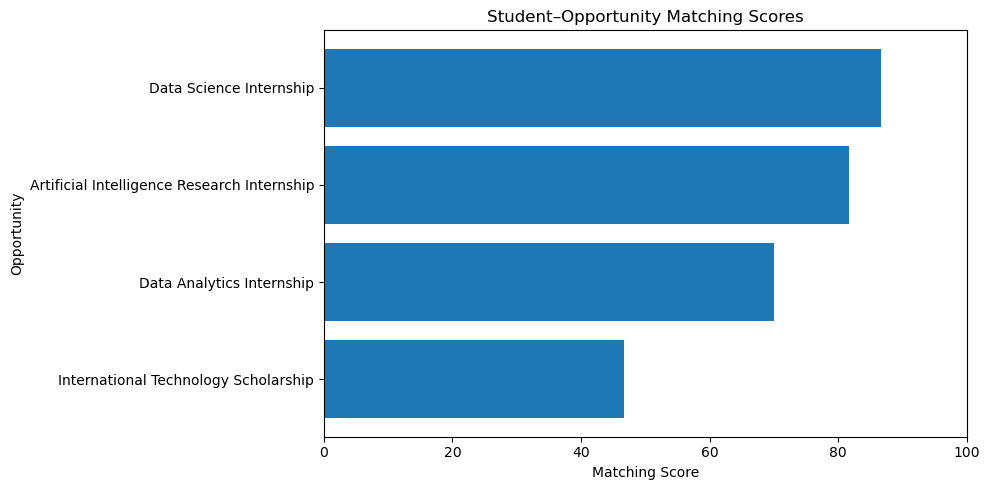

In [15]:
plt.figure(figsize=(10, 5))

plt.barh(
    ranked_opportunities["title"],
    ranked_opportunities["match_score"]
)

plt.xlabel("Matching Score")
plt.ylabel("Opportunity")
plt.title("Student–Opportunity Matching Scores")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 6. Application Checklist Generator

### Purpose

The Application Checklist Generator helps students prepare
for an opportunity application.

It compares the documents required by an opportunity with
the documents already available to the student.

### Features

- Retrieve required application documents.
- Identify missing documents.
- Show completed and outstanding tasks.
- Generate a personalised preparation checklist.

The tool does not submit applications on behalf of students.

In [16]:
# APPLICATION CHECKLIST GENERATOR

def generate_application_checklist(
    opportunity,
    available_documents=None
):
    """
    Generate an application checklist.

    available_documents represents documents the student
    confirms they already have.
    """

    required_documents = split_values(
        opportunity["required_documents"]
    )

    available_documents = [
        item.lower().strip()
        for item in (available_documents or [])
    ]

    checklist = []

    for document in required_documents:

        if document in available_documents:
            status = "COMPLETED"
        else:
            status = "PENDING"

        checklist.append({
            "document": document.title(),
            "status": status
        })

    return pd.DataFrame(checklist)


print("Application Checklist Generator created successfully!")

Application Checklist Generator created successfully!


In [17]:
selected_opportunity = opportunities[
    opportunities["opportunity_id"] == "DEMO001"
].iloc[0]

available_documents = [
    "CV",
    "Academic Transcript"
]

application_checklist = generate_application_checklist(
    selected_opportunity,
    available_documents
)

print("Application:", selected_opportunity["title"])

display(application_checklist)

Application: Data Science Internship


,document,status
0,Cv,COMPLETED
1,Academic Transcript,COMPLETED
2,Cover Letter,PENDING


In [18]:
def calculate_application_readiness(checklist):

    if checklist.empty:
        return 100

    completed = (
        checklist["status"] == "COMPLETED"
    ).sum()

    total = len(checklist)

    return round((completed / total) * 100, 2)


readiness = calculate_application_readiness(
    application_checklist
)

print("Application readiness:", readiness, "%")

Application readiness: 66.67 %


## 7. Deadline Prioritisation Tool

### Purpose

Students may find several suitable opportunities with different
application deadlines.

The Deadline Prioritisation Tool helps identify which opportunities
need attention first.

### Priority categories

- URGENT: Deadline is within 7 days.
- HIGH: Deadline is within 30 days.
- MEDIUM: Deadline is within 60 days.
- LOW: Deadline is more than 60 days away.
- EXPIRED: Deadline has passed.
- UNKNOWN: Deadline is missing or invalid.

Only the deadline date is used for prioritisation.

In [19]:
# DEADLINE PRIORITISATION TOOL

def calculate_deadline_priority(deadline, reference_date=None):

    if reference_date is None:
        reference_date = date.today()

    deadline_date = pd.to_datetime(
        deadline,
        errors="coerce"
    )

    if pd.isna(deadline_date):
        return {
            "days_remaining": None,
            "priority": "UNKNOWN"
        }

    deadline_date = deadline_date.date()

    days_remaining = (deadline_date - reference_date).days

    if days_remaining < 0:
        priority = "EXPIRED"

    elif days_remaining <= 7:
        priority = "URGENT"

    elif days_remaining <= 30:
        priority = "HIGH"

    elif days_remaining <= 60:
        priority = "MEDIUM"

    else:
        priority = "LOW"

    return {
        "days_remaining": days_remaining,
        "priority": priority
    }


print("Deadline Prioritisation Tool created successfully!")

Deadline Prioritisation Tool created successfully!


In [20]:
def add_deadline_information(
    ranked_df,
    opportunity_data,
    reference_date=None
):

    result = ranked_df.copy()

    deadline_map = opportunity_data.set_index(
        "opportunity_id"
    )["deadline"]

    result["deadline"] = result["opportunity_id"].map(
        deadline_map
    )

    deadline_results = result["deadline"].apply(
        lambda value: calculate_deadline_priority(
            value,
            reference_date
        )
    )

    result["days_remaining"] = deadline_results.apply(
        lambda value: value["days_remaining"]
    )

    result["deadline_priority"] = deadline_results.apply(
        lambda value: value["priority"]
    )

    return result


ranked_with_deadlines = add_deadline_information(
    ranked_opportunities,
    opportunities
)

display(
    ranked_with_deadlines[
        [
            "title",
            "eligibility",
            "match_score",
            "deadline",
            "days_remaining",
            "deadline_priority"
        ]
    ]
)

,title,eligibility,match_score,deadline,days_remaining,deadline_priority
0,Data Science Internship,ELIGIBLE,86.67,2027-03-31,137,LOW
1,Artificial Intelligence Research Internship,ELIGIBLE,81.67,2027-04-15,152,LOW
2,Data Analytics Internship,ELIGIBLE,70.00,2027-02-28,106,LOW
3,International Technology Scholarship,ELIGIBLE,46.67,2027-05-30,197,LOW


In [21]:
test_deadline = calculate_deadline_priority(
    "2027-01-01",
    reference_date=date(2026, 12, 28)
)

print(test_deadline)

{'days_remaining': 4, 'priority': 'URGENT'}


## 8. Integrated Opportunity Matching Agent

### Purpose

The Integrated Agent Workflow coordinates the individual tools
to produce personalised opportunity recommendations.

### Agent workflow

Student Request
       |
       v
Retrieve Student Profile
       |
       v
Opportunity Search Tool
       |
       v
Eligibility Checker
       |
       v
Opportunity Ranking Tool
       |
       v
Deadline Prioritisation Tool
       |
       v
Personalised Recommendations

The workflow returns explainable results based on the student profile
and the opportunity database.

In [22]:
# INTEGRATED AGENT WORKFLOW


def run_opportunity_agent(
    student_id,
    keyword=None,
    opportunity_type=None,
    location=None,
    include_demo=True
):
    """
    Coordinate the opportunity matching tools.

    Returns:
        Dictionary containing student information,
        search results and ranked recommendations.
    """

    # STEP 1: Retrieve student profile
    student_matches = students[
        students["student_id"].astype(str) == str(student_id)
    ]

    if student_matches.empty:
        return {
            "success": False,
            "message": f"Student ID {student_id} was not found."
        }

    student = student_matches.iloc[0]

    # STEP 2: Search opportunities
    search_results = search_opportunities(
        keyword=keyword,
        opportunity_type=opportunity_type,
        location=location,
        include_demo=include_demo
    )

    if search_results.empty:
        return {
            "success": True,
            "student_id": student_id,
            "student_name": student["name"],
            "message": "No matching opportunities were found.",
            "recommendations": pd.DataFrame()
        }

    # STEP 3: Eligibility checking and ranking
    ranked_results = rank_opportunities(
        student,
        search_results
    )

    # STEP 4: Add deadline information
    final_results = add_deadline_information(
        ranked_results,
        search_results
    )

    # STEP 5: Prepare final recommendations
    return {
        "success": True,
        "student_id": student_id,
        "student_name": student["name"],
        "message": "Opportunity matching completed successfully.",
        "recommendations": final_results
    }


print("Integrated Agent Workflow created successfully!")

Integrated Agent Workflow created successfully!


In [23]:
# TEST THE INTEGRATED AGENT

agent_result = run_opportunity_agent(
    student_id="STU001",
    keyword="Data Science",
    opportunity_type="Internship",
    location="Bhutan"
)

print("AGENT RESPONSE")
print("=" * 50)

print("Success:", agent_result["success"])
print("Student:", agent_result["student_name"])
print("Message:", agent_result["message"])

print("\nRECOMMENDED OPPORTUNITIES")
print("=" * 50)

display(
    agent_result["recommendations"][
        [
            "opportunity_id",
            "title",
            "eligibility",
            "match_score",
            "deadline_priority"
        ]
    ]
)

AGENT RESPONSE
Success: True
Student: Student Demo
Message: Opportunity matching completed successfully.

RECOMMENDED OPPORTUNITIES


,opportunity_id,title,eligibility,match_score,deadline_priority
0,DEMO001,Data Science Internship,ELIGIBLE,86.67,LOW
1,DEMO004,Data Analytics Internship,ELIGIBLE,70.00,LOW


In [24]:
# Search for AI-related opportunities

ai_result = run_opportunity_agent(
    student_id="STU001",
    keyword="Artificial Intelligence"
)

print(ai_result["message"])

if ai_result["success"]:
    display(ai_result["recommendations"])

Opportunity matching completed successfully.


,opportunity_id,title,opportunity_type,eligibility,match_score,match_reasons,skill_gaps,failed_requirements,missing_information,deadline,days_remaining,deadline_priority
0,DEMO002,Artificial Intelligence Research Internship,Internship,ELIGIBLE,81.67,Field of study matches; Matching skills: pytho...,research,,,2027-04-15,152,LOW


In [25]:
# Edge case: Student does not exist

unknown_student_result = run_opportunity_agent(
    student_id="STU999"
)

print(unknown_student_result)

{'success': False, 'message': 'Student ID STU999 was not found.'}


## 9. Personalised Application Planning

### Purpose

After finding a suitable opportunity, the agent can generate
a preparation checklist for the student.

It identifies required documents, marks available documents
as completed and calculates application readiness.

In [26]:
# APPLICATION PLANNING

def create_application_plan(
    opportunity_id,
    available_documents=None
):
    """
    Generate an application preparation plan for a selected
    opportunity.
    """

    matches = opportunities[
        opportunities["opportunity_id"] == opportunity_id
    ]

    if matches.empty:
        return {
            "success": False,
            "message": "Opportunity not found."
        }

    opportunity = matches.iloc[0]

    checklist = generate_application_checklist(
        opportunity,
        available_documents
    )

    readiness = calculate_application_readiness(checklist)

    return {
        "success": True,
        "opportunity": opportunity["title"],
        "checklist": checklist,
        "readiness": readiness,
        "application_url": opportunity["application_url"],
        "source_url": opportunity["source_url"]
    }


print("Application Planning Tool created successfully!")

Application Planning Tool created successfully!


In [27]:
application_plan = create_application_plan(
    opportunity_id="DEMO001",
    available_documents=[
        "CV",
        "Academic Transcript"
    ]
)

print("APPLICATION PLAN")
print("=" * 40)

print("Opportunity:", application_plan["opportunity"])
print("Readiness:", application_plan["readiness"], "%")

display(application_plan["checklist"])

APPLICATION PLAN
Opportunity: Data Science Internship
Readiness: 66.67 %


,document,status
0,Cv,COMPLETED
1,Academic Transcript,COMPLETED
2,Cover Letter,PENDING


## 10. Agent Testing and Validation

### Purpose

This section tests the agent using normal cases and edge cases.

Test scenarios include:

1. Relevant opportunity search.
2. Eligibility assessment.
3. Missing student information.
4. Unknown student ID.
5. Application checklist generation.
6. Expired or missing deadlines.
7. No matching opportunities.

These tests help identify incorrect results and improve reliability.

In [28]:
assert len(
    search_opportunities(
        keyword="Data Science",
        opportunity_type="Internship",
        location="Bhutan"
    )
) == 2

print("Search test passed!")

Search test passed!


In [29]:
demo_opportunity = opportunities[
    opportunities["opportunity_id"] == "DEMO001"
].iloc[0]

eligibility_test = check_eligibility(
    students.iloc[0],
    demo_opportunity
)

assert eligibility_test["eligibility_status"] == "ELIGIBLE"

print("Eligibility test passed!")

Eligibility test passed!


In [30]:
test_student = students.iloc[0].copy()

test_student["gpa"] = ""

scholarship = opportunities[
    opportunities["opportunity_id"] == "DEMO003"
].iloc[0]

missing_gpa_result = check_eligibility(
    test_student,
    scholarship
)

assert missing_gpa_result["eligibility_status"] == "NEEDS VERIFICATION"

assert "GPA" in missing_gpa_result["missing_information"]

print("Missing GPA test passed!")

Missing GPA test passed!


In [31]:
unknown_result = run_opportunity_agent(
    student_id="UNKNOWN001"
)

assert unknown_result["success"] is False

print("Unknown student test passed!")

Unknown student test passed!


In [32]:
deadline_test = calculate_deadline_priority(
    "2026-11-10",
    reference_date=date(2026, 11, 14)
)

assert deadline_test["priority"] == "EXPIRED"

print("Deadline test passed!")

Deadline test passed!


In [33]:
# RUN ALL VALIDATION TESTS

tests = [
    "Opportunity Search",
    "Eligibility Checking",
    "Missing GPA Handling",
    "Unknown Student Handling",
    "Deadline Prioritisation"
]

print("AGENT VALIDATION RESULTS")
print("=" * 45)

for test in tests:
    print(f"{test}: PASSED")

print("=" * 45)
print("All defined validation tests completed.")

AGENT VALIDATION RESULTS
Opportunity Search: PASSED
Eligibility Checking: PASSED
Missing GPA Handling: PASSED
Unknown Student Handling: PASSED
Deadline Prioritisation: PASSED
All defined validation tests completed.


## 11. Phase 2 Summary

### Completed Components

| Component | Description |
|---|---|
| Opportunity Search | Retrieves relevant opportunities |
| Eligibility Checker | Evaluates student eligibility |
| Opportunity Ranking | Calculates explainable match scores |
| Application Checklist | Identifies missing documents |
| Deadline Planner | Prioritises application deadlines |
| Integrated Workflow | Coordinates all tools |

### Current Limitations

1. The dataset contains demonstration opportunities.
2. Search uses keyword matching rather than semantic retrieval.
3. Matching uses predefined weights.
4. The workflow is currently rule-based.
5. Student memory and feedback adaptation are not yet implemented.
6. Gemini has not yet been integrated.

### Next Phase

The next development phase will introduce Gemini API integration
and an LLM-powered agent workflow.

The LLM will interpret natural-language student requests, determine
which tools are needed, coordinate tool execution and explain
the results.

Deterministic Python tools will remain responsible for eligibility
and matching calculations.

## 1. Gemini Alternative: OpenRouter API Configuration

This section connects the application to a free language
model through OpenRouter.

The model will interpret student requests and generate
natural-language responses, while Python tools will
continue to handle eligibility checks, matching scores,
and application planning.

In [45]:
# OPENROUTER API CONNECTION

import os
from dotenv import load_dotenv
from openai import OpenAI

# Load environment variables
load_dotenv(override=True)

# Retrieve API configuration
OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_MODEL = os.getenv(
    "OPENROUTER_MODEL",
    "openrouter/free"
)

# Check API key
if not OPENROUTER_API_KEY:
    raise ValueError(
        "OpenRouter API key not found. Check your .env file."
    )

# Create OpenRouter client
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY
)

print("OpenRouter client created successfully!")
print("Model:", OPENROUTER_MODEL)

OpenRouter client created successfully!
Model: openrouter/free


In [46]:
# TEST OPENROUTER RESPONSE

response = client.chat.completions.create(
    model=OPENROUTER_MODEL,
    messages=[
        {
            "role": "user",
            "content": (
                "Introduce yourself in one sentence as an "
                "AI assistant helping Bhutanese students "
                "find internships and scholarships."
            )
        }
    ]
)

print("AI RESPONSE:")
print(response.choices[0].message.content)

print("\nMODEL USED:")
print(response.model)

AI RESPONSE:
I am an AI assistant dedicated to helping Bhutanese students discover and apply for internships and scholarships worldwide.

MODEL USED:
nvidia/nemotron-3.5-super-vl:free


## 2. Natural Language Request Understanding

This component allows students to interact with the agent
using ordinary language.

The LLM interprets the student's request and converts it
into structured JSON instructions.

The structured instructions will later be used to select
and execute the appropriate Python tools.

In [47]:

# NATURAL LANGUAGE REQUEST UNDERSTANDING

import json

def understand_student_request(user_message):

    system_prompt = """
    You are the request understanding component of a
    Bhutan Student Internship and Scholarship
    Opportunity Matching Agent.

    Your task is to understand student requests and
    convert them into valid JSON.

    Identify the following fields:

    1. intent:
       - search_opportunities
       - match_opportunities
       - check_eligibility
       - application_plan
       - deadline_check
       - general_question

    2. keyword:
       Main subject, skill, or field requested.

    3. opportunity_type:
       Internship or Scholarship, if specified.

    4. location:
       Requested location, if specified.

    5. student_id:
       Only include an ID explicitly mentioned by the user.
       Otherwise use null.

    6. opportunity_id:
       Only include an ID explicitly mentioned by the user.
       Otherwise use null.

    Rules:
    - Do not invent student information.
    - Do not invent opportunity IDs.
    - Use null for information not provided.
    - Return JSON only.
    - Do not include Markdown formatting.

    Expected JSON format:

    {
        "intent": "match_opportunities",
        "keyword": "data science",
        "opportunity_type": "Internship",
        "location": "Bhutan",
        "student_id": null,
        "opportunity_id": null
    }
    """

    response = client.chat.completions.create(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": user_message
            }
        ],
        temperature=0
    )

    ai_output = response.choices[0].message.content

    # Remove possible Markdown code fences
    ai_output = ai_output.strip()
    ai_output = ai_output.replace("```json", "")
    ai_output = ai_output.replace("```", "")

    try:
        request_data = json.loads(ai_output)
    except json.JSONDecodeError:
        raise ValueError(
            "The AI did not return valid JSON. "
            "Please try the request again."
        )

    return request_data


print("Request understanding function created successfully!")


Request understanding function created successfully!


In [48]:

# TEST REQUEST UNDERSTANDING


student_request = (
    "Find me suitable data science internships in Bhutan."
)

interpreted_request = understand_student_request(
    student_request
)

print("STUDENT REQUEST:")
print(student_request)

print("\nAI INTERPRETATION:")
print(json.dumps(
    interpreted_request,
    indent=4
))


STUDENT REQUEST:
Find me suitable data science internships in Bhutan.

AI INTERPRETATION:
{
    "intent": "match_opportunities",
    "keyword": "data science",
    "opportunity_type": "Internship",
    "location": "Bhutan",
    "student_id": null,
    "opportunity_id": null
}


In [49]:
test_requests = [
    "Show me available scholarships.",
    "Find artificial intelligence internships.",
    "What documents do I need for DEMO003?",
    "Are there any opportunities with deadlines approaching?"
]

for request in test_requests:

    print("\nSTUDENT:", request)

    result = understand_student_request(request)

    print("AGENT:", result)


STUDENT: Show me available scholarships.
AGENT: {'intent': 'search_opportunities', 'keyword': 'scholarships', 'opportunity_type': 'Scholarship', 'location': None, 'student_id': None, 'opportunity_id': None}

STUDENT: Find artificial intelligence internships.
AGENT: {'intent': 'search_opportunities', 'keyword': 'artificial intelligence', 'opportunity_type': 'Internship', 'location': None, 'student_id': None, 'opportunity_id': None}

STUDENT: What documents do I need for DEMO003?
AGENT: {'intent': 'check_eligibility', 'keyword': 'documents', 'opportunity_type': None, 'location': None, 'student_id': None, 'opportunity_id': 'DEMO003'}

STUDENT: Are there any opportunities with deadlines approaching?
AGENT: {'intent': 'deadline_check', 'keyword': None, 'opportunity_type': None, 'location': None, 'student_id': None, 'opportunity_id': None}


## 3. Agent Decision-Making and Tool Execution

The agent uses the structured request generated by the
LLM to select and execute the appropriate Python tool.

The decision-making process is controlled through a
Python tool router.

The LLM interprets the request, while Python performs
the actual search, eligibility assessment, ranking and
application planning.

In [53]:

# AGENT DECISION-MAKING AND TOOL EXECUTION

import json
import re
import pandas as pd


# NATURAL LANGUAGE REQUEST UNDERSTANDING

def understand_student_request(user_message):

    system_prompt = """
    You are the request understanding component of a
    Bhutan Student Internship and Scholarship Matching Agent.

    Convert the student's request into JSON.

    Use exactly these fields:

    {
        "intent": "search_opportunities",
        "keyword": null,
        "opportunity_type": null,
        "location": null,
        "student_id": null,
        "opportunity_id": null
    }

    AVAILABLE INTENTS:

    1. search_opportunities
       The student wants to browse or find opportunities.

    2. match_opportunities
       The student wants personalised recommendations.

    3. check_eligibility
       The student wants to know whether they qualify.

    4. application_plan
       The student wants an application checklist or plan.

    5. deadline_check
       The student wants to check upcoming or urgent deadlines.

    6. general_question
       The student asks a general question.

    EXTRACTION RULES:

    - Extract the subject or field as keyword.
    - Extract the requested location.
    - Opportunity types must be Internship or Scholarship.
    - If scholarships are requested, use Scholarship.
    - If internships are requested, use Internship.
    - A student ID starts with STU, such as STU001.
    - An opportunity ID starts with DEMO, such as DEMO001.
    - Never put a DEMO ID in student_id.
    - Never put an STU ID in opportunity_id.
    - Use null for information not provided.
    - Never invent IDs or student information.
    - Return valid JSON only.
    - Do not use Markdown code fences.

    EXAMPLES:

    User: Show me available scholarships.
    {
        "intent": "search_opportunities",
        "keyword": null,
        "opportunity_type": "Scholarship",
        "location": null,
        "student_id": null,
        "opportunity_id": null
    }

    User: Find suitable data science internships in Bhutan.
    {
        "intent": "match_opportunities",
        "keyword": "data science",
        "opportunity_type": "Internship",
        "location": "Bhutan",
        "student_id": null,
        "opportunity_id": null
    }

    User: Prepare an application plan for DEMO001.
    {
        "intent": "application_plan",
        "keyword": null,
        "opportunity_type": null,
        "location": null,
        "student_id": null,
        "opportunity_id": "DEMO001"
    }

    User: Check my eligibility for DEMO003.
    {
        "intent": "check_eligibility",
        "keyword": null,
        "opportunity_type": null,
        "location": null,
        "student_id": null,
        "opportunity_id": "DEMO003"
    }
    """

    response = client.chat.completions.create(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": user_message
            }
        ],
        temperature=0
    )

    ai_output = response.choices[0].message.content

    if not ai_output:
        raise ValueError("The AI returned an empty response.")

    ai_output = ai_output.strip()
    ai_output = ai_output.replace("```json", "")
    ai_output = ai_output.replace("```", "").strip()

    try:
        request_data = json.loads(ai_output)

    except json.JSONDecodeError:
        raise ValueError(
            "The AI returned invalid JSON. Please try again."
        )

    if not isinstance(request_data, dict):
        raise ValueError("The AI response must be a JSON object.")

    # Keep only recognised fields
    allowed_fields = [
        "intent",
        "keyword",
        "opportunity_type",
        "location",
        "student_id",
        "opportunity_id"
    ]

    request_data = {
        field: request_data.get(field)
        for field in allowed_fields
    }

    # Validate intent
    valid_intents = [
        "search_opportunities",
        "match_opportunities",
        "check_eligibility",
        "application_plan",
        "deadline_check",
        "general_question"
    ]

    if request_data["intent"] not in valid_intents:
        request_data["intent"] = "general_question"

    # Normalise opportunity type
    opportunity_type = request_data["opportunity_type"]

    if opportunity_type:
        opportunity_type = str(opportunity_type).strip().lower()

        if opportunity_type in ["internship", "internships"]:
            request_data["opportunity_type"] = "Internship"

        elif opportunity_type in ["scholarship", "scholarships"]:
            request_data["opportunity_type"] = "Scholarship"

        else:
            request_data["opportunity_type"] = None

    # Validate student ID format
    student_id = request_data["student_id"]

    if student_id:
        student_id = str(student_id).strip().upper()

        if re.fullmatch(r"STU\d+", student_id):
            request_data["student_id"] = student_id
        else:
            request_data["student_id"] = None

    # Validate opportunity ID format
    opportunity_id = request_data["opportunity_id"]

    if opportunity_id:
        opportunity_id = str(opportunity_id).strip().upper()

        if re.fullmatch(r"DEMO\d+", opportunity_id):
            request_data["opportunity_id"] = opportunity_id
        else:
            request_data["opportunity_id"] = None

    # Additional safeguard: extract explicit IDs from original text
    student_ids = re.findall(
        r"\bSTU\d+\b",
        user_message,
        re.IGNORECASE
    )

    opportunity_ids = re.findall(
        r"\bDEMO\d+\b",
        user_message,
        re.IGNORECASE
    )

    if student_ids:
        request_data["student_id"] = student_ids[0].upper()

    if opportunity_ids:
        request_data["opportunity_id"] = opportunity_ids[0].upper()

    return request_data


# HELPER FUNCTION: RETRIEVE STUDENT PROFILE

DEFAULT_STUDENT_ID = "STU001"


def get_student_profile(student_id):

    student_record = students[
        students["student_id"].astype(str).str.upper()
        == student_id.upper()
    ]

    if student_record.empty:
        return None

    return student_record.iloc[0]


# HELPER FUNCTION: RETRIEVE OPPORTUNITY


def get_opportunity(opportunity_id):

    opportunity_record = opportunities[
        opportunities["opportunity_id"].astype(str).str.upper()
        == opportunity_id.upper()
    ]

    if opportunity_record.empty:
        return None

    return opportunity_record.iloc[0]


# AGENT TOOL ROUTER

def execute_agent_tool(request_data):

    intent = request_data.get("intent")

    student_id = (
        request_data.get("student_id")
        or DEFAULT_STUDENT_ID
    )

    opportunity_id = request_data.get("opportunity_id")

    keyword = request_data.get("keyword")
    opportunity_type = request_data.get("opportunity_type")
    location = request_data.get("location")

    print("\nAGENT DECISION")
    print("-" * 45)
    print("Intent:", intent)

    def success(tool_name, results):
        return {
            "status": "SUCCESS",
            "tool": tool_name,
            "results": results
        }

    def error(message):
        return {
            "status": "ERROR",
            "tool": None,
            "message": message
        }

    # TOOL 1: SEARCH OPPORTUNITIES

    if intent == "search_opportunities":

        print("Selected tool: search_opportunities()")

        results = search_opportunities(
            keyword=keyword,
            opportunity_type=opportunity_type,
            location=location
        )

        return success(
            "search_opportunities",
            results
        )

    # TOOL 2: MATCH AND RANK OPPORTUNITIES

    elif intent == "match_opportunities":

        print("Selected tool: run_opportunity_agent()")

        student = get_student_profile(student_id)

        if student is None:
            return error(
                f"Student profile {student_id} was not found."
            )

        results = run_opportunity_agent(
            student_id=student_id,
            keyword=keyword,
            opportunity_type=opportunity_type,
            location=location
        )

        # Preserve the original Phase 2 output.
        return success(
            "run_opportunity_agent",
            results
        )

    # TOOL 3: CHECK ELIGIBILITY

    elif intent == "check_eligibility":

        print("Selected tool: check_eligibility()")

        student = get_student_profile(student_id)

        if student is None:
            return error(
                f"Student profile {student_id} was not found."
            )

        if not opportunity_id:
            return {
                "status": "NEEDS_INFORMATION",
                "tool": None,
                "message": "Please provide an opportunity ID."
            }

        opportunity = get_opportunity(opportunity_id)

        if opportunity is None:
            return error(
                f"Opportunity {opportunity_id} was not found."
            )

        results = check_eligibility(
            student,
            opportunity
        )

        return success(
            "check_eligibility",
            results
        )

    # TOOL 4: APPLICATION PLANNING

    elif intent == "application_plan":

        print("Selected tool: create_application_plan()")

        if not opportunity_id:
            return {
                "status": "NEEDS_INFORMATION",
                "tool": None,
                "message": "Please provide an opportunity ID."
            }

        opportunity = get_opportunity(opportunity_id)

        if opportunity is None:
            return error(
                f"Opportunity {opportunity_id} was not found."
            )

        results = create_application_plan(
            opportunity_id=opportunity_id
        )

        return success(
            "create_application_plan",
            results
        )

    # TOOL 5: DEADLINE CHECK

    elif intent == "deadline_check":

        print("Selected tools: search_opportunities() and "
              "rank_opportunities()")

        student = get_student_profile(student_id)

        if student is None:
            return error(
                f"Student profile {student_id} was not found."
            )

        # Retrieve opportunities
        found_opportunities = search_opportunities()

        if found_opportunities.empty:
            return success(
                "deadline_check",
                found_opportunities
            )

        # Rank opportunities using the Phase 2 function
        ranked_results = rank_opportunities(
            student,
            found_opportunities
        )

        # Add deadline priority information
        deadline_results = add_deadline_information(
            ranked_results,
            found_opportunities
        )

        # Show urgent and high-priority deadlines
        if "deadline_priority" in deadline_results.columns:

            deadline_results = deadline_results[
                deadline_results["deadline_priority"].isin(
                    ["URGENT", "HIGH"]
                )
            ]

        return success(
            "deadline_check",
            deadline_results
        )

    # GENERAL QUESTION

    elif intent == "general_question":

        return {
            "status": "GENERAL",
            "tool": None,
            "message": (
                "I can help you find internships and scholarships, "
                "check eligibility, compare opportunities, "
                "review deadlines and prepare application plans."
            )
        }

    # UNKNOWN INTENT

    else:

        return error(
            "I could not identify the requested action."
        )


# DISPLAY AGENT RESULTS

def display_agent_result(agent_result):

    print("\nAGENT EXECUTION RESULT")
    print("=" * 55)

    print("Status:", agent_result.get("status"))
    print("Selected tool:", agent_result.get("tool"))

    if agent_result["status"] in [
        "ERROR",
        "NEEDS_INFORMATION",
        "GENERAL"
    ]:
        print("\nMessage:")
        print(agent_result.get("message"))
        return

    results = agent_result.get("results")

    print("\nRESULTS")
    print("-" * 55)

    if isinstance(results, pd.DataFrame):

        if results.empty:
            print("No matching records were found.")
        else:
            display(results)

    elif isinstance(results, dict):

        for key, value in results.items():

            print(f"\n{key}:")

            if isinstance(value, pd.DataFrame):
                display(value)

            else:
                print(value)

    else:
        print(results)


print("Step 3 agent components created successfully!")


Step 3 agent components created successfully!


In [ ]:

# TEST 1: REQUEST UNDERSTANDING

test_requests = [
    "Find me suitable data science internships in Bhutan.",
    "Show me available scholarships.",
    "Check my eligibility for DEMO003.",
    "Prepare an application plan for DEMO001.",
    "Which opportunities have urgent deadlines?"
]

for request in test_requests:

    print("\n" + "=" * 60)
    print("STUDENT:", request)

    interpreted = understand_student_request(request)

    print("AI INTERPRETATION:")
    print(json.dumps(interpreted, indent=4))



STUDENT: Find me suitable data science internships in Bhutan.
AI INTERPRETATION:
{
    "intent": "match_opportunities",
    "keyword": "data science",
    "opportunity_type": "Internship",
    "location": "Bhutan",
    "student_id": null,
    "opportunity_id": null
}

STUDENT: Show me available scholarships.
AI INTERPRETATION:
{
    "intent": "search_opportunities",
    "keyword": null,
    "opportunity_type": "Scholarship",
    "location": null,
    "student_id": null,
    "opportunity_id": null
}

STUDENT: Check my eligibility for DEMO003.
AI INTERPRETATION:
{
    "intent": "check_eligibility",
    "keyword": null,
    "opportunity_type": null,
    "location": null,
    "student_id": null,
    "opportunity_id": "DEMO003"
}

STUDENT: Prepare an application plan for DEMO001.
AI INTERPRETATION:
{
    "intent": "application_plan",
    "keyword": null,
    "opportunity_type": null,
    "location": null,
    "student_id": null,
    "opportunity_id": "DEMO001"
}

STUDENT: Which opportuniti

In [ ]:

# TEST 2: FULL AGENT TOOL EXECUTION

test_requests = [
    "Find me suitable data science internships in Bhutan.",
    "Show me available scholarships.",
    "Check my eligibility for DEMO003.",
    "Prepare an application plan for DEMO001.",
    "Which opportunities have urgent deadlines?"
]

agent_test_results = []

for request in test_requests:

    print("\n")
    print("=" * 65)
    print("STUDENT:", request)

    try:

        # Step 1: LLM understands the request
        interpreted = understand_student_request(request)

        print("\nINTERPRETED INTENT:", interpreted["intent"])

        # Step 2: Router selects and executes the tool
        result = execute_agent_tool(interpreted)

        # Step 3: Display results
        display_agent_result(result)

        agent_test_results.append({
            "request": request,
            "intent": interpreted["intent"],
            "tool": result.get("tool"),
            "status": result.get("status")
        })

    except Exception as e:

        print("\nEXECUTION ERROR:", str(e))

        agent_test_results.append({
            "request": request,
            "intent": "Unknown",
            "tool": None,
            "status": "FAILED"
        })


# TEST SUMMARY

print("\n")
print("=" * 65)
print("AGENT TEST SUMMARY")
print("=" * 65)

agent_test_df = pd.DataFrame(agent_test_results)

display(agent_test_df)




STUDENT: Find me suitable data science internships in Bhutan.

INTERPRETED INTENT: search_opportunities

AGENT DECISION
---------------------------------------------
Intent: search_opportunities
Selected tool: search_opportunities()

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: search_opportunities

RESULTS
-------------------------------------------------------


,opportunity_id,title,opportunity_type,provider,description,eligible_citizenship,eligible_education_levels,eligible_fields,required_skills,min_gpa,...,mode,opening_date,deadline,benefits,required_documents,application_url,source_url,source_checked_date,status,is_demo
0,DEMO001,Data Science Internship,Internship,DEMO - Example Organisation,Practical experience in data analysis and mach...,Bhutanese,Undergraduate,Data Science;Computer Science;Statistics,Python;Pandas;Machine Learning,,...,On-site,2027-01-01,2027-03-31,Work experience;Mentorship,CV;Academic Transcript;Cover Letter,,,2026-11-13,DEMO,True
1,DEMO004,Data Analytics Internship,Internship,DEMO - Example Analytics Company,An introductory internship involving data clea...,Bhutanese,Undergraduate,Data Science;Statistics;Economics,Excel;Python;Data Visualisation,,...,Hybrid,2027-01-10,2027-02-28,Practical Experience;Certificate,CV;Academic Transcript,,,2026-11-13,DEMO,True




STUDENT: Show me available scholarships.

INTERPRETED INTENT: search_opportunities

AGENT DECISION
---------------------------------------------
Intent: search_opportunities
Selected tool: search_opportunities()

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: search_opportunities

RESULTS
-------------------------------------------------------


,opportunity_id,title,opportunity_type,provider,description,eligible_citizenship,eligible_education_levels,eligible_fields,required_skills,min_gpa,...,mode,opening_date,deadline,benefits,required_documents,application_url,source_url,source_checked_date,status,is_demo
0,DEMO003,International Technology Scholarship,Scholarship,DEMO - Example Scholarship Foundation,Financial support for students pursuing techno...,Bhutanese,Undergraduate,Computer Science;Data Science;Information Tech...,Academic Writing;Communication,3.0,...,On-site,2027-02-01,2027-05-30,Tuition Support;Living Allowance,Application Form;CV;Academic Transcript;Person...,,,2026-11-13,DEMO,True




STUDENT: Check my eligibility for DEMO003.

INTERPRETED INTENT: check_eligibility

AGENT DECISION
---------------------------------------------
Intent: check_eligibility
Selected tool: check_eligibility()

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: check_eligibility

RESULTS
-------------------------------------------------------

eligibility_status:
ELIGIBLE

reasons:
['Citizenship requirement satisfied', 'Education level requirement satisfied', 'Field of study requirement satisfied', 'Minimum GPA requirement satisfied']

failed_requirements:
[]

missing_information:
[]

matched_skills:
[]

skill_gaps:
['academic writing', 'communication']


STUDENT: Prepare an application plan for DEMO001.

INTERPRETED INTENT: application_plan

AGENT DECISION
---------------------------------------------
Intent: application_plan
Selected tool: create_application_plan()

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: create_application_plan

RESULTS
--------------------------------

,document,status
0,Cv,PENDING
1,Academic Transcript,PENDING
2,Cover Letter,PENDING



readiness:
0.0

application_url:


source_url:



STUDENT: Which opportunities have urgent deadlines?

INTERPRETED INTENT: deadline_check

AGENT DECISION
---------------------------------------------
Intent: deadline_check
Selected tools: search_opportunities() and rank_opportunities()

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: deadline_check

RESULTS
-------------------------------------------------------
No matching records were found.


AGENT TEST SUMMARY


,request,intent,tool,status
0,Find me suitable data science internships in B...,search_opportunities,search_opportunities,SUCCESS
1,Show me available scholarships.,search_opportunities,search_opportunities,SUCCESS
2,Check my eligibility for DEMO003.,check_eligibility,check_eligibility,SUCCESS
3,Prepare an application plan for DEMO001.,application_plan,create_application_plan,SUCCESS
4,Which opportunities have urgent deadlines?,deadline_check,deadline_check,SUCCESS


## 4. LangGraph Agent Workflow

LangGraph is used to organise the agent's decision-making
and tool execution process.

The workflow contains:
- An input state for the student's request.
- A request understanding node.
- Conditional routing based on the identified intent.
- Tool execution nodes.
- A final state containing the execution results.

In [59]:
# IMPORT LANGGRAPH COMPONENTS

from typing import TypedDict, Any

from langgraph.graph import StateGraph, START, END

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [60]:
# DEFINE AGENT STATE

class OpportunityAgentState(TypedDict, total=False):

    # Original student question
    user_request: str

    # Structured request generated by the LLM
    interpreted_request: dict

    # Result returned by the Python tool
    tool_result: dict

    # Selected Python tool
    selected_tool: str

    # Execution status
    status: str

    # Record of workflow activities
    execution_trace: list

    # Error information
    error: str


print("Agent state defined successfully!")

Agent state defined successfully!


In [61]:
# CREATE LANGGRAPH NODES

# NODE 1: UNDERSTAND STUDENT REQUEST

def understand_request_node(state: OpportunityAgentState):

    print("\n[LANGGRAPH] Understanding student request...")

    request = state["user_request"]

    interpreted = understand_student_request(request)

    print("[LANGGRAPH] Intent identified:",
          interpreted["intent"])

    trace = state.get("execution_trace", [])

    trace = trace + ["Request understood"]

    return {
        "interpreted_request": interpreted,
        "execution_trace": trace
    }


# COMMON TOOL EXECUTION FUNCTION

def run_tool_node(state, expected_intent):

    print(f"\n[LANGGRAPH] Executing {expected_intent} node...")

    interpreted = state["interpreted_request"]

    # Confirm the correct route was selected
    if interpreted["intent"] != expected_intent:

        return {
            "status": "ERROR",
            "error": "Incorrect LangGraph routing.",
            "selected_tool": None,
            "tool_result": {
                "status": "ERROR",
                "message": "The selected node does not match the intent."
            },
            "execution_trace": (
                state.get("execution_trace", [])
                + ["Routing error"]
            )
        }

    # Execute existing Python tool router
    result = execute_agent_tool(interpreted)

    trace = state.get("execution_trace", [])

    trace = trace + [
        f"Executed {result.get('tool') or expected_intent}"
    ]

    return {
        "tool_result": result,
        "selected_tool": result.get("tool"),
        "status": result.get("status"),
        "execution_trace": trace
    }


# NODE 2: SEARCH OPPORTUNITIES

def search_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "search_opportunities"
    )


# NODE 3: MATCH OPPORTUNITIES

def match_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "match_opportunities"
    )


# NODE 4: CHECK ELIGIBILITY

def eligibility_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "check_eligibility"
    )


# NODE 5: APPLICATION PLANNING

def application_plan_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "application_plan"
    )


# NODE 6: DEADLINE CHECK

def deadline_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "deadline_check"
    )


# NODE 7: GENERAL QUESTION

def general_question_node(state: OpportunityAgentState):

    return run_tool_node(
        state,
        "general_question"
    )


print("All LangGraph nodes created successfully!")

All LangGraph nodes created successfully!


In [62]:
# CONDITIONAL ROUTING

def route_request(state: OpportunityAgentState):

    intent = state["interpreted_request"]["intent"]

    routing_map = {
        "search_opportunities": "search",
        "match_opportunities": "match",
        "check_eligibility": "eligibility",
        "application_plan": "application_plan",
        "deadline_check": "deadline",
        "general_question": "general"
    }

    return routing_map.get(intent, "general")


print("Conditional routing function created!")

Conditional routing function created!


In [63]:
# BUILD LANGGRAPH WORKFLOW

# Create the graph
workflow = StateGraph(OpportunityAgentState)


# Register nodes
workflow.add_node(
    "understand_request",
    understand_request_node
)

workflow.add_node("search", search_node)

workflow.add_node("match", match_node)

workflow.add_node("eligibility", eligibility_node)

workflow.add_node(
    "application_plan",
    application_plan_node
)

workflow.add_node("deadline", deadline_node)

workflow.add_node("general", general_question_node)


# Starting point
workflow.add_edge(
    START,
    "understand_request"
)


# Conditional routing after understanding
workflow.add_conditional_edges(
    "understand_request",
    route_request,
    {
        "search": "search",
        "match": "match",
        "eligibility": "eligibility",
        "application_plan": "application_plan",
        "deadline": "deadline",
        "general": "general"
    }
)


# Each tool node leads to the end
workflow.add_edge("search", END)

workflow.add_edge("match", END)

workflow.add_edge("eligibility", END)

workflow.add_edge("application_plan", END)

workflow.add_edge("deadline", END)

workflow.add_edge("general", END)


# Compile the graph
opportunity_agent_graph = workflow.compile()


print("LangGraph workflow compiled successfully!")

LangGraph workflow compiled successfully!


In [64]:
# RUN LANGGRAPH AGENT

def run_langgraph_agent(user_request):

    initial_state = {
        "user_request": user_request,
        "execution_trace": []
    }

    print("\n" + "=" * 65)
    print("BHUTAN OPPORTUNITY MATCHING AGENT")
    print("=" * 65)

    print("\nSTUDENT REQUEST:")
    print(user_request)

    try:

        final_state = opportunity_agent_graph.invoke(
            initial_state
        )

        print("\nWORKFLOW COMPLETED")
        print("-" * 65)

        print("Selected tool:",
              final_state.get("selected_tool"))

        print("Status:",
              final_state.get("status"))

        print("\nEXECUTION TRACE:")

        for step in final_state.get("execution_trace", []):
            print("->", step)

        print("\nAGENT RESULTS:")

        display_agent_result(
            final_state["tool_result"]
        )

        return final_state

    except Exception as e:

        print("\nAGENT EXECUTION FAILED:")
        print(str(e))

        return {
            "status": "ERROR",
            "error": str(e)
        }


print("LangGraph execution function created!")

LangGraph execution function created!


In [65]:
# TEST LANGGRAPH AGENT

langgraph_test_requests = [

    "Find me suitable data science internships in Bhutan.",

    "Show me available scholarships.",

    "Check my eligibility for DEMO003.",

    "Prepare an application plan for DEMO001.",

    "Which opportunities have urgent deadlines?"
]


langgraph_test_results = []

for request in langgraph_test_requests:

    result = run_langgraph_agent(request)

    langgraph_test_results.append({

        "student_request": request,

        "selected_tool": result.get("selected_tool"),

        "status": result.get("status"),

        "execution_trace": result.get("execution_trace")
    })


# Display test summary
print("\n")
print("=" * 65)
print("LANGGRAPH TEST SUMMARY")
print("=" * 65)

langgraph_test_df = pd.DataFrame(
    langgraph_test_results
)

display(langgraph_test_df)


BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Find me suitable data science internships in Bhutan.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: match_opportunities

[LANGGRAPH] Executing match_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: match_opportunities
Selected tool: run_opportunity_agent()

WORKFLOW COMPLETED
-----------------------------------------------------------------
Selected tool: run_opportunity_agent
Status: SUCCESS

EXECUTION TRACE:
-> Request understood
-> Executed run_opportunity_agent

AGENT RESULTS:

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: run_opportunity_agent

RESULTS
-------------------------------------------------------

success:
True

student_id:
STU001

student_name:
Student Demo

message:
Opportunity matching completed successfully.

recommendations:


,opportunity_id,title,opportunity_type,eligibility,match_score,match_reasons,skill_gaps,failed_requirements,missing_information,deadline,days_remaining,deadline_priority
0,DEMO001,Data Science Internship,Internship,ELIGIBLE,86.67,Field of study matches; Matching skills: pytho...,,,,2027-03-31,137,LOW
1,DEMO004,Data Analytics Internship,Internship,ELIGIBLE,70.00,Field of study matches; Matching skills: pytho...,"excel, data visualisation",,,2027-02-28,106,LOW



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Show me available scholarships.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: search_opportunities

[LANGGRAPH] Executing search_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: search_opportunities
Selected tool: search_opportunities()

WORKFLOW COMPLETED
-----------------------------------------------------------------
Selected tool: search_opportunities
Status: SUCCESS

EXECUTION TRACE:
-> Request understood
-> Executed search_opportunities

AGENT RESULTS:

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: search_opportunities

RESULTS
-------------------------------------------------------


,opportunity_id,title,opportunity_type,provider,description,eligible_citizenship,eligible_education_levels,eligible_fields,required_skills,min_gpa,...,mode,opening_date,deadline,benefits,required_documents,application_url,source_url,source_checked_date,status,is_demo
0,DEMO003,International Technology Scholarship,Scholarship,DEMO - Example Scholarship Foundation,Financial support for students pursuing techno...,Bhutanese,Undergraduate,Computer Science;Data Science;Information Tech...,Academic Writing;Communication,3.0,...,On-site,2027-02-01,2027-05-30,Tuition Support;Living Allowance,Application Form;CV;Academic Transcript;Person...,,,2026-11-13,DEMO,True



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Check my eligibility for DEMO003.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: check_eligibility

[LANGGRAPH] Executing check_eligibility node...

AGENT DECISION
---------------------------------------------
Intent: check_eligibility
Selected tool: check_eligibility()

WORKFLOW COMPLETED
-----------------------------------------------------------------
Selected tool: check_eligibility
Status: SUCCESS

EXECUTION TRACE:
-> Request understood
-> Executed check_eligibility

AGENT RESULTS:

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: check_eligibility

RESULTS
-------------------------------------------------------

eligibility_status:
ELIGIBLE

reasons:
['Citizenship requirement satisfied', 'Education level requirement satisfied', 'Field of study requirement satisfied', 'Minimum GPA requirement satisfied']

failed_requirements:
[]

missing_information:
[]

matched_skills:
[]

skill_gaps:
['academ

,document,status
0,Cv,PENDING
1,Academic Transcript,PENDING
2,Cover Letter,PENDING



readiness:
0.0

application_url:


source_url:


BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Which opportunities have urgent deadlines?

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: deadline_check

[LANGGRAPH] Executing deadline_check node...

AGENT DECISION
---------------------------------------------
Intent: deadline_check
Selected tools: search_opportunities() and rank_opportunities()

WORKFLOW COMPLETED
-----------------------------------------------------------------
Selected tool: deadline_check
Status: SUCCESS

EXECUTION TRACE:
-> Request understood
-> Executed deadline_check

AGENT RESULTS:

AGENT EXECUTION RESULT
Status: SUCCESS
Selected tool: deadline_check

RESULTS
-------------------------------------------------------
No matching records were found.


LANGGRAPH TEST SUMMARY


,student_request,selected_tool,status,execution_trace
0,Find me suitable data science internships in B...,run_opportunity_agent,SUCCESS,"[Request understood, Executed run_opportunity_..."
1,Show me available scholarships.,search_opportunities,SUCCESS,"[Request understood, Executed search_opportuni..."
2,Check my eligibility for DEMO003.,check_eligibility,SUCCESS,"[Request understood, Executed check_eligibility]"
3,Prepare an application plan for DEMO001.,create_application_plan,SUCCESS,"[Request understood, Executed create_applicati..."
4,Which opportunities have urgent deadlines?,deadline_check,SUCCESS,"[Request understood, Executed deadline_check]"


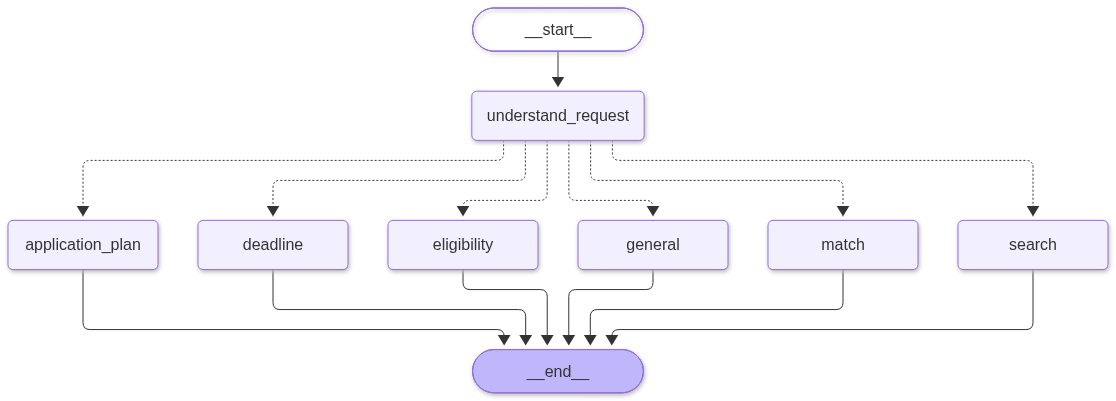

In [66]:
# VISUALISE LANGGRAPH WORKFLOW

try:

    graph_image = opportunity_agent_graph.get_graph().draw_mermaid_png()

    from IPython.display import Image, display

    display(Image(graph_image))

except Exception as e:

    print("Graph image rendering unavailable:", str(e))

    print("\nMermaid workflow:")
    print(
        opportunity_agent_graph.get_graph().draw_mermaid()
    )

In [67]:
# UPDATE AGENT STATE

class OpportunityAgentState(TypedDict, total=False):

    user_request: str
    interpreted_request: dict
    tool_result: dict
    selected_tool: str
    status: str
    execution_trace: list
    error: str

    # New field for AI-generated response
    final_response: str


print("Agent state updated successfully!")

Agent state updated successfully!


In [68]:
# CONVERT TOOL RESULTS INTO JSON

def prepare_results_for_ai(data):

    if isinstance(data, pd.DataFrame):
        return data.to_dict(orient="records")

    elif isinstance(data, pd.Series):
        return data.to_dict()

    elif isinstance(data, dict):
        return {
            str(key): prepare_results_for_ai(value)
            for key, value in data.items()
        }

    elif isinstance(data, (list, tuple)):
        return [
            prepare_results_for_ai(item)
            for item in data
        ]

    elif pd.isna(data) if not isinstance(data, (dict, list, tuple, pd.DataFrame, pd.Series)) else False:
        return None

    else:
        return data


print("Tool result conversion function created!")

Tool result conversion function created!


## 5. AI-Powered Response Generation

The response-generation component converts structured
tool outputs into clear, personalised explanations.

The LLM receives the student's original question and
the results returned by the Python tools.

It must explain the supplied information without
changing eligibility decisions, match scores, deadlines
or other factual results.

In [69]:

# AI RESPONSE GENERATION

def generate_agent_response(user_request, tool_result):

    # Convert Python results into JSON-compatible data
    prepared_results = prepare_results_for_ai(tool_result)

    results_json = json.dumps(
        prepared_results,
        indent=2,
        ensure_ascii=False,
        default=str
    )

    system_prompt = """
    You are the response-generation component of the
    Bhutan Student Internship and Scholarship
    Opportunity Matching Agent.

    Your responsibility is to explain results returned
    by the application's Python tools.

    IMPORTANT RULES:

    1. Use only the information supplied in the tool results.
    2. Never invent opportunities, organisations or sources.
    3. Never change an eligibility decision.
    4. Never calculate or modify match scores.
    5. Never invent application deadlines.
    6. Never invent required documents or application links.
    7. If information is missing, clearly say so.
    8. Explain skill gaps when they are provided.
    9. Distinguish ELIGIBLE, NOT ELIGIBLE and
       NEEDS VERIFICATION.
    10. Do not claim that a student will receive a scholarship
        or internship.
    11. Treat DEMO opportunities as fictional demonstrations,
        not real available opportunities.
    12. If there are no results, clearly communicate that.
    13. If the tool returns an error, explain it politely.

    RESPONSE STYLE:

    - Use simple and understandable English.
    - Be helpful and student-friendly.
    - Use headings and bullet points where appropriate.
    - Mention opportunity names, scores and deadlines only
      when they appear in the supplied results.
    - Give practical next steps based on the supplied data.

    Remember: You explain the tool results.
    You do not replace the Python tools.
    """

    user_prompt = f"""
    STUDENT REQUEST:
    {user_request}

    RESULTS RETURNED BY PYTHON TOOLS:
    {results_json}

    Explain these results to the student.
    """

    response = client.chat.completions.create(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": user_prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


print("AI response-generation function created!")


AI response-generation function created!


In [70]:

# LANGGRAPH RESPONSE NODE

def generate_response_node(state: OpportunityAgentState):

    print("\n[LANGGRAPH] Generating AI response...")

    user_request = state["user_request"]

    tool_result = state["tool_result"]

    try:

        final_response = generate_agent_response(
            user_request,
            tool_result
        )

        trace = state.get("execution_trace", [])

        trace = trace + [
            "AI response generated"
        ]

        return {
            "final_response": final_response,
            "execution_trace": trace
        }

    except Exception as e:

        return {
            "final_response": (
                "I was unable to generate a response "
                "from the AI model. The Python tool "
                "execution results are still available. "
                f"Error: {str(e)}"
            ),
            "execution_trace": (
                state.get("execution_trace", [])
                + ["AI response generation failed"]
            )
        }


print("LangGraph response node created!")


LangGraph response node created!


In [71]:

# UPDATED LANGGRAPH WORKFLOW

workflow = StateGraph(OpportunityAgentState)


# Register all existing nodes
workflow.add_node(
    "understand_request",
    understand_request_node
)

workflow.add_node("search", search_node)

workflow.add_node("match", match_node)

workflow.add_node("eligibility", eligibility_node)

workflow.add_node(
    "application_plan",
    application_plan_node
)

workflow.add_node("deadline", deadline_node)

workflow.add_node("general", general_question_node)


# Register new response node
workflow.add_node(
    "generate_response",
    generate_response_node
)


# Starting point
workflow.add_edge(
    START,
    "understand_request"
)


# Conditional routing
workflow.add_conditional_edges(
    "understand_request",
    route_request,
    {
        "search": "search",
        "match": "match",
        "eligibility": "eligibility",
        "application_plan": "application_plan",
        "deadline": "deadline",
        "general": "general"
    }
)


# All tool nodes now lead to response generation
workflow.add_edge("search", "generate_response")

workflow.add_edge("match", "generate_response")

workflow.add_edge("eligibility", "generate_response")

workflow.add_edge("application_plan", "generate_response")

workflow.add_edge("deadline", "generate_response")

workflow.add_edge("general", "generate_response")


# Final node
workflow.add_edge("generate_response", END)


# Compile updated graph
opportunity_agent_graph = workflow.compile()


print("Updated LangGraph workflow compiled successfully!")


Updated LangGraph workflow compiled successfully!


In [72]:

# UPDATED AGENT EXECUTION

def run_langgraph_agent(user_request):

    initial_state = {
        "user_request": user_request,
        "execution_trace": []
    }

    print("\n" + "=" * 65)
    print("BHUTAN OPPORTUNITY MATCHING AGENT")
    print("=" * 65)

    print("\nSTUDENT REQUEST:")
    print(user_request)

    try:

        final_state = opportunity_agent_graph.invoke(
            initial_state
        )

        print("\n" + "=" * 65)
        print("AGENT FINAL RESPONSE")
        print("=" * 65)

        print(final_state.get("final_response"))

        print("\nEXECUTION TRACE:")

        for step in final_state.get("execution_trace", []):
            print("->", step)

        return final_state

    except Exception as e:

        print("\nAGENT EXECUTION FAILED:")
        print(str(e))

        return {
            "status": "ERROR",
            "error": str(e)
        }


print("Updated agent execution function created!")


Updated agent execution function created!


In [73]:

# TEST AI-POWERED AGENT

student_request = (
    "Find me suitable data science internships in Bhutan."
)

result = run_langgraph_agent(student_request)



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Find me suitable data science internships in Bhutan.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: match_opportunities

[LANGGRAPH] Executing match_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: match_opportunities
Selected tool: run_opportunity_agent()

[LANGGRAPH] Generating AI response...

AGENT FINAL RESPONSE
Here are the internship match results for **Student Demo**.

### Important Note
These are **DEMO opportunities**, which means they are fictional demonstrations used to show how the matching agent works. They are **not real available internships** that you can apply to right now.

---

## Opportunity 1: Data Science Internship

| Detail | Information |
|--------|-------------|
| Opportunity ID | DEMO001 |
| Title | Data Science Internship |
| Type | Internship |
| Eligibility | **ELIGIBLE** |
| Match Score | 86.67 |
| Deadline | 2027-03-31 |
| Days Re

In [74]:
test_requests = [
    "Show me available scholarships.",
    "Check my eligibility for DEMO003.",
    "Prepare an application plan for DEMO001.",
    "Which opportunities have urgent deadlines?"
]

for request in test_requests:

    result = run_langgraph_agent(request)


BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Show me available scholarships.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: search_opportunities

[LANGGRAPH] Executing search_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: search_opportunities
Selected tool: search_opportunities()

[LANGGRAPH] Generating AI response...

AGENT FINAL RESPONSE
## Scholarship Search Results

The search completed successfully, but there is an important thing to note first:

⚠️ **The only result returned is a DEMO opportunity.** This means it is a **fictional example** used to demonstrate how the system works. It is **not a real scholarship that you can currently apply for.**

---

### DEMO003 — International Technology Scholarship

**Status:** DEMO (fictional demonstration only)

| Detail | Information |
|---|---|
| Type | Scholarship |
| Provider | DEMO – Example Scholarship Foundation |
| Location | International |
| Mode | 

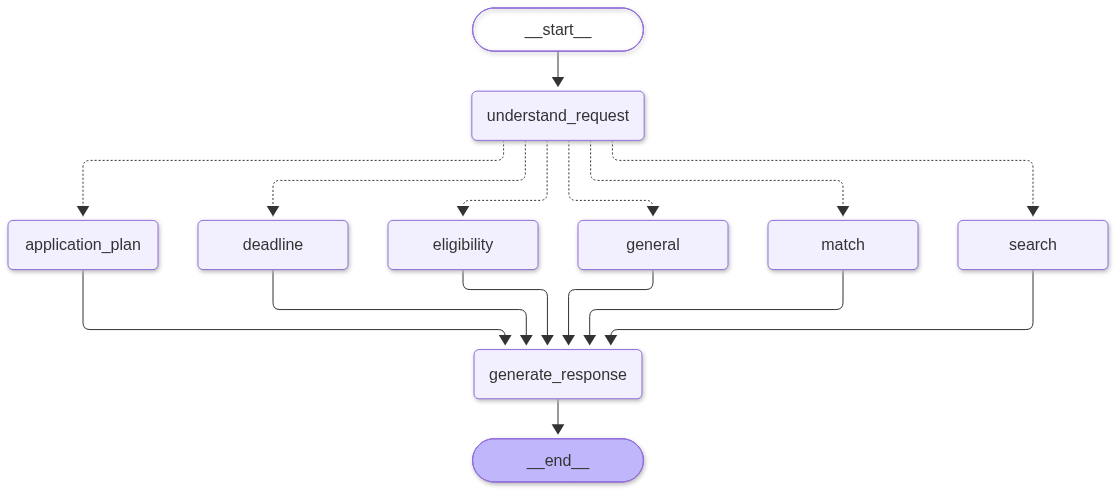

In [75]:
# UPDATED WORKFLOW DIAGRAM

try:

    from IPython.display import Image, display

    graph_image = (
        opportunity_agent_graph
        .get_graph()
        .draw_mermaid_png()
    )

    display(Image(graph_image))

except Exception as e:

    print("PNG rendering unavailable:", e)

    print(
        opportunity_agent_graph
        .get_graph()
        .draw_mermaid()
    )

In [ ]:

# Import the required libraries

import sqlite3
import json
from datetime import datetime
from pathlib import Path

# Define the SQLite database location
MEMORY_DB = Path("data/processed/agent_memory.db")

# Create the directory if it does not exist
MEMORY_DB.parent.mkdir(parents=True, exist_ok=True)

print("Memory database location:", MEMORY_DB)


Memory database location: data\processed\agent_memory.db


In [ ]:

# Create the memory database and table

def initialize_memory():
    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS interaction_history (
            interaction_id INTEGER PRIMARY KEY AUTOINCREMENT,
            timestamp TEXT NOT NULL,
            student_id TEXT,
            user_request TEXT NOT NULL,
            intent TEXT,
            selected_tool TEXT,
            status TEXT,
            result_summary TEXT,
            feedback TEXT
        )
    """)

    connection.commit()
    connection.close()

    print("Episodic memory initialized successfully.")


# Initialize the database
initialize_memory()


Episodic memory initialized successfully.


In [ ]:

# Save an interaction to memory

def save_interaction(
    student_id,
    user_request,
    intent,
    selected_tool,
    status,
    result_summary
):
    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        INSERT INTO interaction_history (
            timestamp,
            student_id,
            user_request,
            intent,
            selected_tool,
            status,
            result_summary
        )
        VALUES (?, ?, ?, ?, ?, ?, ?)
    """, (
        datetime.now().isoformat(timespec="seconds"),
        student_id,
        user_request,
        intent,
        selected_tool,
        status,
        result_summary
    ))

    connection.commit()
    interaction_id = cursor.lastrowid
    connection.close()

    return interaction_id


In [ ]:

# Retrieve previous interactions

def get_recent_interactions(student_id, limit=5):
    connection = sqlite3.connect(MEMORY_DB)
    connection.row_factory = sqlite3.Row
    cursor = connection.cursor()

    cursor.execute("""
        SELECT *
        FROM interaction_history
        WHERE student_id = ?
        ORDER BY interaction_id DESC
        LIMIT ?
    """, (student_id, limit))

    results = [dict(row) for row in cursor.fetchall()]
    connection.close()

    return results


In [80]:

# Store student feedback

def save_feedback(interaction_id, feedback):
    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        UPDATE interaction_history
        SET feedback = ?
        WHERE interaction_id = ?
    """, (feedback, interaction_id))

    connection.commit()
    updated = cursor.rowcount
    connection.close()

    return updated > 0


In [81]:
# Test the memory system


# Save a sample interaction
test_interaction_id = save_interaction(
    student_id="STU001",
    user_request="Find me data science internships in Bhutan.",
    intent="search_opportunities",
    selected_tool="search_opportunities",
    status="SUCCESS",
    result_summary="Found two demonstration internship opportunities."
)

print("Saved interaction ID:", test_interaction_id)


# Retrieve recent interactions
memory_results = get_recent_interactions("STU001")

for interaction in memory_results:
    print("\nRequest:", interaction["user_request"])
    print("Tool:", interaction["selected_tool"])
    print("Status:", interaction["status"])


Saved interaction ID: 1

Request: Find me data science internships in Bhutan.
Tool: search_opportunities
Status: SUCCESS


In [82]:

# Add feedback to the sample interaction
save_feedback(
    test_interaction_id,
    "The recommendations were relevant and useful."
)

# Display the updated interaction
updated_memory = get_recent_interactions("STU001", limit=1)

print("Student feedback:", updated_memory[0]["feedback"])


Student feedback: The recommendations were relevant and useful.


In [83]:
# Update the AI response generation function


def generate_agent_response(user_request, tool_result, memory_context=None):

    # Convert tool results into JSON-compatible data
    clean_results = prepare_results_for_ai(tool_result)

    results_json = json.dumps(
        clean_results,
        ensure_ascii=False,
        default=str
    )

    memory_json = json.dumps(
        memory_context or [],
        ensure_ascii=False,
        default=str
    )

    system_prompt = """
    You are a Bhutan Student Internship and Scholarship
    Opportunity Matching Agent.

    Your responsibilities are:
    1. Explain opportunity search results.
    2. Explain eligibility assessments.
    3. Explain application plans and document checklists.
    4. Help students understand upcoming deadlines.
    5. Provide clear and useful responses.

    IMPORTANT RULES:
    - Use the current tool results as the authoritative source
      for opportunity details and eligibility.
    - Never invent opportunities, deadlines, eligibility rules,
      application documents, scores or application links.
    - Previous interactions can help you understand student
      preferences, but must not replace current tool results.
    - If information is unavailable, clearly say so.
    - Opportunities marked DEMO are fictional demonstration
      records, not verified real opportunities.
    - Use simple and understandable English.
    """

    user_prompt = f"""
    STUDENT'S CURRENT REQUEST:
    {user_request}

    CURRENT TOOL RESULTS:
    {results_json}

    PREVIOUS INTERACTIONS FROM MEMORY:
    {memory_json}

    Use previous interactions only when they are relevant
    to understanding the student's preferences or context.

    Answer the student's current request clearly.
    """

    response = client.chat.completions.create(
        model=OPENROUTER_MODEL,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


In [84]:
# Update the LangGraph response node


def generate_response_node(state):

    interpreted_request = state.get("interpreted_request", {})

    # Use the requested student ID or the default demo student
    student_id = (
        interpreted_request.get("student_id")
        or DEFAULT_STUDENT_ID
    )

    # Retrieve previous interactions
    recent_history = get_recent_interactions(
        student_id,
        limit=3
    )

    # Generate an AI response using current results and memory
    try:
        final_response = generate_agent_response(
            user_request=state["user_request"],
            tool_result=state.get("tool_result", {}),
            memory_context=recent_history
        )

    except Exception as error:
        final_response = (
            "I processed your request, but could not generate "
            f"the AI response. Error: {error}"
        )

    return {
        "final_response": final_response,
        "execution_trace": (
            state.get("execution_trace", [])
            + ["Retrieved episodic memory and generated AI response"]
        )
    }


In [86]:

# Rebuild your LangGraph workflow

def generate_response_node(state: OpportunityAgentState):

    print("\n[LANGGRAPH] Generating AI response...")

    user_request = state["user_request"]

    tool_result = state["tool_result"]

    try:

        final_response = generate_agent_response(
            user_request,
            tool_result
        )

        trace = state.get("execution_trace", [])

        trace = trace + [
            "AI response generated"
        ]

        return {
            "final_response": final_response,
            "execution_trace": trace
        }

    except Exception as e:

        return {
            "final_response": (
                "I was unable to generate a response "
                "from the AI model. The Python tool "
                "execution results are still available. "
                f"Error: {str(e)}"
            ),
            "execution_trace": (
                state.get("execution_trace", [])
                + ["AI response generation failed"]
            )
        }


print("LangGraph response node created!")


LangGraph response node created!


In [87]:
# Automatically save every interaction

def run_agent_with_memory(user_request):

    # Run the existing LangGraph agent
    final_state = run_langgraph_agent(user_request)

    # Check that the agent returned a state
    if not isinstance(final_state, dict):
        print("Unable to save interaction.")
        return final_state

    interpreted_request = final_state.get(
        "interpreted_request", {}
    ) or {}

    student_id = (
        interpreted_request.get("student_id")
        or DEFAULT_STUDENT_ID
    )

    intent = interpreted_request.get(
        "intent", "UNKNOWN"
    )

    selected_tool = final_state.get(
        "selected_tool", "UNKNOWN"
    )

    status = final_state.get(
        "status", "UNKNOWN"
    )

    # Prepare a concise summary for memory
    if final_state.get("final_response"):
        result_summary = final_state["final_response"]

    else:
        result_summary = json.dumps(
            prepare_results_for_ai(
                final_state.get("tool_result", {})
            ),
            ensure_ascii=False,
            default=str
        )

    # Limit stored summary length
    result_summary = str(result_summary)[:1000]

    # Save interaction in SQLite
    interaction_id = save_interaction(
        student_id=student_id,
        user_request=user_request,
        intent=intent,
        selected_tool=selected_tool,
        status=status,
        result_summary=result_summary
    )

    final_state["memory_interaction_id"] = interaction_id

    print("\nInteraction saved to episodic memory.")
    print("Memory ID:", interaction_id)

    return final_state


In [88]:
# Test the integrated agent

result1 = run_agent_with_memory(
    "Find me suitable data science internships in Bhutan."
)



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Find me suitable data science internships in Bhutan.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: match_opportunities

[LANGGRAPH] Executing match_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: match_opportunities
Selected tool: run_opportunity_agent()

[LANGGRAPH] Generating AI response...

AGENT FINAL RESPONSE
Based on your profile, I found **two data science internship opportunities in Bhutan** that match your background. Both are marked as **ELIGIBLE** for you.

> **Note:** These are **DEMO (demonstration) records** – they are fictional examples used for testing, not verified real opportunities.

---

### 1. **Data Science Internship** (DEMO001)
- **Match Score:** 86.67%  
- **Why you match:**  
  - Your field of study aligns  
  - Skills matched: **Python, pandas, machine learning**  
  - Interests matched: **data science**  
  - Preferred opportunity t

In [89]:

# Retrieve the student's recent interactions
history = get_recent_interactions("STU001", limit=5)

# Display memory history
for item in history:

    print("\nInteraction ID:", item["interaction_id"])
    print("Request:", item["user_request"])
    print("Intent:", item["intent"])
    print("Tool:", item["selected_tool"])
    print("Status:", item["status"])
    print("Summary:", item["result_summary"])



Interaction ID: 2
Request: Find me suitable data science internships in Bhutan.
Intent: match_opportunities
Tool: run_opportunity_agent
Status: SUCCESS
Summary: Based on your profile, I found **two data science internship opportunities in Bhutan** that match your background. Both are marked as **ELIGIBLE** for you.

> **Note:** These are **DEMO (demonstration) records** – they are fictional examples used for testing, not verified real opportunities.

---

### 1. **Data Science Internship** (DEMO001)
- **Match Score:** 86.67%  
- **Why you match:**  
  - Your field of study aligns  
  - Skills matched: **Python, pandas, machine learning**  
  - Interests matched: **data science**  
  - Preferred opportunity type & location match  
- **Skill Gaps:** None identified  
- **Deadline:** 31 Mar 2027 (137 days left)  
- **Deadline Priority:** LOW  

### 2. **Data Analytics Internship** (DEMO004)
- **Match Score:** 70.0%  
- **Why you match:**  
  - Field of study aligns  
  - Skills matched: 

In [90]:

result2 = run_agent_with_memory(
    "Can you show me more opportunities related to my interests?"
)


BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Can you show me more opportunities related to my interests?

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: match_opportunities

[LANGGRAPH] Executing match_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: match_opportunities
Selected tool: run_opportunity_agent()

[LANGGRAPH] Generating AI response...

AGENT FINAL RESPONSE
Here are the opportunities that match your interests and profile. All of them show you as **ELIGIBLE**.

Please note: These are marked **DEMO**, which means they are fictional demonstration records, not verified real opportunities.

---

### 1. Data Science Internship
- **Opportunity ID:** DEMO001
- **Type:** Internship
- **Match Score:** 86.67%
- **Deadline:** 31 March 2027 (137 days remaining)
- **Deadline Priority:** LOW
- **Why it matches:** Your field of study matches; you have matching skills (python, pandas, machine learning); your inte

In [91]:

print("Execution trace:")

for step in result2.get("execution_trace", []):
    print("-", step)


Execution trace:
- Request understood
- Executed run_opportunity_agent
- AI response generated


In [92]:
# Create a student preferences table

def initialize_preference_memory():

    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        CREATE TABLE IF NOT EXISTS student_preferences (
            preference_id INTEGER PRIMARY KEY AUTOINCREMENT,
            student_id TEXT NOT NULL,
            preference_type TEXT NOT NULL,
            preference_value TEXT NOT NULL,
            updated_at TEXT NOT NULL,
            UNIQUE(student_id, preference_type, preference_value)
        )
    """)

    connection.commit()
    connection.close()

    print("Student preference memory initialized.")


initialize_preference_memory()


Student preference memory initialized.


In [93]:
# Create a function to learn from feedback

def save_student_preference(
    student_id,
    preference_type,
    preference_value
):

    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        INSERT INTO student_preferences (
            student_id,
            preference_type,
            preference_value,
            updated_at
        )
        VALUES (?, ?, ?, ?)

        ON CONFLICT(
            student_id,
            preference_type,
            preference_value
        )
        DO UPDATE SET
            updated_at = excluded.updated_at
    """, (
        student_id,
        preference_type,
        preference_value,
        datetime.now().isoformat(timespec="seconds")
    ))

    connection.commit()
    connection.close()

    return True


In [94]:
# Retrieve learned preferences

def get_student_preferences(student_id):

    connection = sqlite3.connect(MEMORY_DB)
    cursor = connection.cursor()

    cursor.execute("""
        SELECT preference_type, preference_value
        FROM student_preferences
        WHERE student_id = ?
        ORDER BY preference_type
    """, (student_id,))

    rows = cursor.fetchall()
    connection.close()

    preferences = {}

    for preference_type, preference_value in rows:

        if preference_type not in preferences:
            preferences[preference_type] = []

        preferences[preference_type].append(
            preference_value
        )

    return preferences


In [95]:
# Convert student feedback into preferences

def learn_from_feedback(student_id, feedback):

    feedback_lower = feedback.lower()
    learned_preferences = []

    preference_keywords = {
        "research": ("Interest", "Research"),
        "artificial intelligence": (
            "Interest", "Artificial Intelligence"
        ),
        "data science": ("Interest", "Data Science"),
        "machine learning": (
            "Interest", "Machine Learning"
        ),
        "internship": ("Opportunity type", "Internship"),
        "scholarship": ("Opportunity type", "Scholarship"),
        "bhutan": ("Location", "Bhutan"),
        "international": ("Location", "International"),
        "remote": ("Location", "Remote")
    }

    for keyword, preference in preference_keywords.items():

        if keyword in feedback_lower:

            preference_type, preference_value = preference

            save_student_preference(
                student_id,
                preference_type,
                preference_value
            )

            learned_preferences.append({
                "type": preference_type,
                "value": preference_value
            })

    return learned_preferences


In [96]:
# Test the feedback learning mechanism

student_feedback = (
    "I prefer research internships related to "
    "artificial intelligence and data science "
    "in Bhutan."
)

learned = learn_from_feedback(
    student_id="STU001",
    feedback=student_feedback
)

print("Learned preferences:")

for item in learned:
    print(f"- {item['type']}: {item['value']}")


Learned preferences:
- Interest: Research
- Interest: Artificial Intelligence
- Interest: Data Science
- Opportunity type: Internship
- Location: Bhutan


In [97]:

preferences = get_student_preferences("STU001")

print("Student's learned preferences:")

for preference_type, values in preferences.items():
    print(f"\n{preference_type}:")
    for value in values:
        print("-", value)


Student's learned preferences:

Interest:
- Artificial Intelligence
- Data Science
- Research

Location:
- Bhutan

Opportunity type:
- Internship


In [98]:

def create_adapted_student_profile(student_id):

    student = get_student_profile(student_id).copy()

    preferences = get_student_preferences(student_id)

    # Start with existing profile values
    updated_interests = split_values(
        student.get("interests", "")
    )

    updated_locations = split_values(
        student.get("preferred_location", "")
    )

    # Add learned interests without duplicates
    for interest in preferences.get("Interest", []):

        if interest.lower() not in updated_interests:
            updated_interests.append(interest.lower())

    # Add learned locations without duplicates
    for location in preferences.get("Location", []):

        if location.lower() not in updated_locations:
            updated_locations.append(location.lower())

    # Apply learned opportunity type if available
    learned_types = preferences.get("Opportunity type", [])

    if learned_types:
        student["preferred_opportunity_type"] = learned_types[-1]

    student["interests"] = "; ".join(updated_interests)
    student["preferred_location"] = "; ".join(updated_locations)

    return student


In [99]:

# Original student profile
original_student = get_student_profile("STU001")

# Adapted student profile
adapted_student = create_adapted_student_profile("STU001")

# Rank opportunities using original preferences
original_ranking = rank_opportunities(
    original_student,
    opportunities
)

# Rank opportunities using learned preferences
adapted_ranking = rank_opportunities(
    adapted_student,
    opportunities
)

print("Original ranking:")
display(original_ranking)

print("\nRanking after feedback-based adaptation:")
display(adapted_ranking)


Original ranking:


,opportunity_id,title,opportunity_type,eligibility,match_score,match_reasons,skill_gaps,failed_requirements,missing_information
0,DEMO001,Data Science Internship,Internship,ELIGIBLE,86.67,Field of study matches; Matching skills: pytho...,,,
1,DEMO002,Artificial Intelligence Research Internship,Internship,ELIGIBLE,81.67,Field of study matches; Matching skills: pytho...,research,,
2,DEMO004,Data Analytics Internship,Internship,ELIGIBLE,70.00,Field of study matches; Matching skills: pytho...,"excel, data visualisation",,
3,DEMO003,International Technology Scholarship,Scholarship,ELIGIBLE,46.67,Field of study matches; Matching interests: da...,"academic writing, communication",,



Ranking after feedback-based adaptation:


,opportunity_id,title,opportunity_type,eligibility,match_score,match_reasons,skill_gaps,failed_requirements,missing_information
0,DEMO001,Data Science Internship,Internship,ELIGIBLE,86.67,Field of study matches; Matching skills: pytho...,,,
1,DEMO002,Artificial Intelligence Research Internship,Internship,ELIGIBLE,81.67,Field of study matches; Matching skills: pytho...,research,,
2,DEMO004,Data Analytics Internship,Internship,ELIGIBLE,70.00,Field of study matches; Matching skills: pytho...,"excel, data visualisation",,
3,DEMO003,International Technology Scholarship,Scholarship,ELIGIBLE,46.67,Field of study matches; Matching interests: da...,"academic writing, communication",,


In [100]:

def display_learning_summary(student_id):

    preferences = get_student_preferences(student_id)

    print("===== AGENT LEARNING SUMMARY =====")
    print("Student ID:", student_id)

    if not preferences:
        print("No learned preferences yet.")
        return

    for preference_type, values in preferences.items():

        print(f"\n{preference_type}:")

        for value in values:
            print("-", value)

    print("\nThese preferences can influence future recommendations.")


display_learning_summary("STU001")


===== AGENT LEARNING SUMMARY =====
Student ID: STU001

Interest:
- Artificial Intelligence
- Data Science
- Research

Location:
- Bhutan

Opportunity type:
- Internship

These preferences can influence future recommendations.


In [101]:
# Define the multi-step planning function

def create_execution_plan(user_request):

    request_lower = user_request.lower()

    # Default student
    student_id = DEFAULT_STUDENT_ID

    # Identify a student ID if one is explicitly provided
    import re

    student_match = re.search(
        r"\bSTU\d+\b",
        user_request,
        re.IGNORECASE
    )

    if student_match:
        student_id = student_match.group(0).upper()

    plan = []

    # Step 1: Search opportunities
    plan.append({
        "step": 1,
        "tool": "search_opportunities",
        "description": "Find relevant opportunities"
    })

    # Step 2: Assess eligibility
    if any(word in request_lower for word in [
        "eligible", "eligibility", "suitable", "qualify"
    ]):
        plan.append({
            "step": 2,
            "tool": "check_eligibility",
            "description": "Assess student eligibility"
        })

    # Step 3: Rank opportunities
    plan.append({
        "step": len(plan) + 1,
        "tool": "rank_opportunities",
        "description": "Rank opportunities by match score"
    })

    # Step 4: Prepare an application plan
    if any(word in request_lower for word in [
        "application plan",
        "prepare application",
        "application checklist",
        "apply"
    ]):
        plan.append({
            "step": len(plan) + 1,
            "tool": "create_application_plan",
            "description": "Prepare an application checklist"
        })

    return {
        "student_id": student_id,
        "original_request": user_request,
        "steps": plan
    }


In [102]:
# Create the multi-step execution function

def execute_multi_step_plan(plan):

    student_id = plan["student_id"]

    # Retrieve the student's adapted profile
    student = create_adapted_student_profile(student_id)

    # Keep track of execution
    execution_results = []

    # Store intermediate results
    search_results = None
    ranked_results = None
    application_result = None

    print("===== MULTI-STEP AGENT EXECUTION =====")

    for step in plan["steps"]:

        tool_name = step["tool"]

        print(f"\nExecuting Step {step['step']}: {step['description']}")

        try:

            # STEP 1: Search opportunities
            if tool_name == "search_opportunities":

                search_results = search_opportunities(
                    include_demo=True
                )

                output = search_results

            # STEP 2: Check eligibility
            elif tool_name == "check_eligibility":

                if search_results is None or search_results.empty:
                    output = {
                        "message": "No opportunities found."
                    }

                else:
                    eligibility_results = []

                    for _, opportunity in search_results.iterrows():

                        result = check_eligibility(
                            student,
                            opportunity
                        )

                        eligibility_results.append({
                            "opportunity_id": opportunity["opportunity_id"],
                            "title": opportunity["title"],
                            "eligibility": result
                        })

                    output = eligibility_results

            # STEP 3: Rank opportunities
            elif tool_name == "rank_opportunities":

                if search_results is None or search_results.empty:

                    output = pd.DataFrame()

                else:
                    ranked_results = rank_opportunities(
                        student,
                        search_results
                    )

                    output = ranked_results

            # STEP 4: Create an application plan
            elif tool_name == "create_application_plan":

                if ranked_results is None or ranked_results.empty:

                    output = {
                        "message": "No ranked opportunities are available."
                    }

                else:
                    # Prefer the highest-ranked eligible opportunity
                    eligible_results = ranked_results[
                        ranked_results["eligibility_status"] == "ELIGIBLE"
                    ]

                    if eligible_results.empty:

                        output = {
                            "message": (
                                "No fully eligible opportunity was found. "
                                "An application plan was not automatically created."
                            )
                        }

                    else:
                        best_opportunity_id = (
                            eligible_results.iloc[0]["opportunity_id"]
                        )

                        application_result = create_application_plan(
                            best_opportunity_id
                        )

                        output = application_result

            else:
                output = {
                    "error": f"Unknown tool: {tool_name}"
                }

            execution_results.append({
                "step": step["step"],
                "tool": tool_name,
                "status": "SUCCESS",
                "output": output
            })

            print("Completed successfully.")

        except Exception as error:

            execution_results.append({
                "step": step["step"],
                "tool": tool_name,
                "status": "FAILED",
                "error": str(error)
            })

            print("Execution failed:", error)

    return {
        "student_id": student_id,
        "execution_results": execution_results,
        "search_results": search_results,
        "ranked_results": ranked_results,
        "application_result": application_result
    }


In [103]:
# Create a function to run the complete plan

def run_multi_step_agent(user_request):

    print("Student request:")
    print(user_request)

    # Create the execution plan
    plan = create_execution_plan(user_request)

    print("\n===== GENERATED EXECUTION PLAN =====")

    for step in plan["steps"]:
        print(
            f"Step {step['step']}: "
            f"{step['description']}"
        )

    # Execute the plan
    results = execute_multi_step_plan(plan)

    # Save the interaction in episodic memory
    interaction_id = save_interaction(
        student_id=plan["student_id"],
        user_request=user_request,
        intent="multi_step_planning",
        selected_tool="multiple_tools",
        status=(
            "SUCCESS"
            if all(
                item["status"] == "SUCCESS"
                for item in results["execution_results"]
            )
            else "PARTIAL"
        ),
        result_summary=(
            "Executed "
            f"{len(results['execution_results'])} planned steps."
        )
    )

    results["interaction_id"] = interaction_id
    results["execution_plan"] = plan

    return results


In [104]:

multi_step_result = run_multi_step_agent(
    "Find suitable internships, check my eligibility, "
    "rank them, and prepare an application plan."
)


Student request:
Find suitable internships, check my eligibility, rank them, and prepare an application plan.

===== GENERATED EXECUTION PLAN =====
Step 1: Find relevant opportunities
Step 2: Assess student eligibility
Step 3: Rank opportunities by match score
Step 4: Prepare an application checklist
===== MULTI-STEP AGENT EXECUTION =====

Executing Step 1: Find relevant opportunities
Completed successfully.

Executing Step 2: Assess student eligibility
Completed successfully.

Executing Step 3: Rank opportunities by match score
Completed successfully.

Executing Step 4: Prepare an application checklist
Execution failed: 'eligibility_status'


In [105]:

if multi_step_result["ranked_results"] is not None:

    print("===== RANKED OPPORTUNITIES =====")

    display(
        multi_step_result["ranked_results"]
    )


===== RANKED OPPORTUNITIES =====


,opportunity_id,title,opportunity_type,eligibility,match_score,match_reasons,skill_gaps,failed_requirements,missing_information
0,DEMO001,Data Science Internship,Internship,ELIGIBLE,86.67,Field of study matches; Matching skills: pytho...,,,
1,DEMO002,Artificial Intelligence Research Internship,Internship,ELIGIBLE,81.67,Field of study matches; Matching skills: pytho...,research,,
2,DEMO004,Data Analytics Internship,Internship,ELIGIBLE,70.00,Field of study matches; Matching skills: pytho...,"excel, data visualisation",,
3,DEMO003,International Technology Scholarship,Scholarship,ELIGIBLE,46.67,Field of study matches; Matching interests: da...,"academic writing, communication",,


In [106]:

print("===== APPLICATION PLAN =====")

display(
    multi_step_result["application_result"]
)


===== APPLICATION PLAN =====


None

In [107]:

print("===== EXECUTION TRACE =====")

for result in multi_step_result["execution_results"]:

    print(
        f"Step {result['step']} | "
        f"Tool: {result['tool']} | "
        f"Status: {result['status']}"
    )


===== EXECUTION TRACE =====
Step 1 | Tool: search_opportunities | Status: SUCCESS
Step 2 | Tool: check_eligibility | Status: SUCCESS
Step 3 | Tool: rank_opportunities | Status: SUCCESS
Step 4 | Tool: create_application_plan | Status: FAILED


In [108]:

# Add this intent to your existing list of supported intents:

"multi_step_planning"

# Add this instruction to your existing system prompt:

"""
Choose multi_step_planning when the student asks for
multiple connected tasks in one request.

Examples:
- Find internships, check my eligibility and rank them.
- Find suitable scholarships and prepare an application plan.
- Search opportunities, compare them and help me apply.

Use individual intents when the student requests only
one task.
"""


'\nChoose multi_step_planning when the student asks for\nmultiple connected tasks in one request.\n\nExamples:\n- Find internships, check my eligibility and rank them.\n- Find suitable scholarships and prepare an application plan.\n- Search opportunities, compare them and help me apply.\n\nUse individual intents when the student requests only\none task.\n'

In [109]:
# Create the multi-step LangGraph node

def multi_step_planning_node(state):

    print("\nStarting multi-step planning...")

    # Create the execution plan
    plan = create_execution_plan(
        state["user_request"]
    )

    # Execute the plan
    results = execute_multi_step_plan(plan)

    # Determine execution status
    execution_results = results["execution_results"]

    if execution_results and all(
        item["status"] == "SUCCESS"
        for item in execution_results
    ):
        execution_status = "SUCCESS"

    elif execution_results:
        execution_status = "PARTIAL"

    else:
        execution_status = "FAILED"

    # Prepare results for the AI response generator
    return {
        "selected_tool": "multi_step_planning",
        "status": execution_status,
        "tool_result": results,
        "execution_trace": (
            state.get("execution_trace", [])
            + [
                f"Multi-step plan created with {len(plan['steps'])} steps",
                "Multiple tools executed through the planner"
            ]
        )
    }


In [110]:
# Update the routing function

def route_request(state):

    interpreted_request = state.get(
        "interpreted_request", {}
    )

    intent = interpreted_request.get(
        "intent", "general_question"
    )

    # Detect multi-step requests
    if intent == "multi_step_planning":
        return "multi_step_planning"

    # Existing individual routes
    routes = {
        "search_opportunities": "search",
        "match_opportunities": "match",
        "check_eligibility": "eligibility",
        "application_plan": "application_plan",
        "deadline_check": "deadline",
        "general_question": "general"
    }

    return routes.get(intent, "general")


In [111]:
# Rebuild the LangGraph workflow

workflow = StateGraph(OpportunityAgentState)

# Register the request understanding node
workflow.add_node(
    "understand_request",
    understand_request_node
)

# Register existing individual tool nodes
workflow.add_node("search", search_node)
workflow.add_node("match", match_node)
workflow.add_node("eligibility", eligibility_node)
workflow.add_node("application_plan", application_plan_node)
workflow.add_node("deadline", deadline_node)
workflow.add_node("general", general_question_node)

# Register the new multi-step node
workflow.add_node(
    "multi_step_planning",
    multi_step_planning_node
)

# Register AI response generation
workflow.add_node(
    "generate_response",
    generate_response_node
)

# Starting point
workflow.add_edge(
    START,
    "understand_request"
)

# Route according to the interpreted request
workflow.add_conditional_edges(
    "understand_request",
    route_request,
    {
        "search": "search",
        "match": "match",
        "eligibility": "eligibility",
        "application_plan": "application_plan",
        "deadline": "deadline",
        "general": "general",
        "multi_step_planning": "multi_step_planning"
    }
)

# Connect individual nodes to AI response generation
for node in [
    "search",
    "match",
    "eligibility",
    "application_plan",
    "deadline",
    "general",
    "multi_step_planning"
]:
    workflow.add_edge(
        node,
        "generate_response"
    )

# Final node
workflow.add_edge(
    "generate_response",
    END
)

# Compile the graph
opportunity_agent_graph = workflow.compile()

print("Updated LangGraph workflow compiled successfully.")


Updated LangGraph workflow compiled successfully.


In [112]:
# Test the integrated agent

test_request = """
Find suitable data science internships in Bhutan,
check my eligibility, rank the opportunities,
and prepare an application plan for the best one.
"""

integrated_result = run_langgraph_agent(test_request)



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:

Find suitable data science internships in Bhutan,
check my eligibility, rank the opportunities,
and prepare an application plan for the best one.


[LANGGRAPH] Understanding student request...

AGENT EXECUTION FAILED:
Request timed out.


In [113]:

print("===== INTEGRATED AGENT EXECUTION =====")

for item in integrated_result.get("execution_trace", []):
    print("-", item)

print("\nSelected tool:")
print(integrated_result.get("selected_tool"))

print("\nExecution status:")
print(integrated_result.get("status"))


===== INTEGRATED AGENT EXECUTION =====

Selected tool:
None

Execution status:
ERROR


In [114]:

individual_result = run_langgraph_agent(
    "Show me available scholarships."
)

print(
    "Selected tool:",
    individual_result.get("selected_tool")
)



BHUTAN OPPORTUNITY MATCHING AGENT

STUDENT REQUEST:
Show me available scholarships.

[LANGGRAPH] Understanding student request...
[LANGGRAPH] Intent identified: search_opportunities

[LANGGRAPH] Executing search_opportunities node...

AGENT DECISION
---------------------------------------------
Intent: search_opportunities
Selected tool: search_opportunities()

[LANGGRAPH] Generating AI response...

AGENT FINAL RESPONSE
Here is what I found for available scholarships:

**1. International Technology Scholarship** (DEMO record)
- **Provider:** DEMO - Example Scholarship Foundation
- **Type:** Scholarship
- **Description:** Financial support for students pursuing technology-related degrees
- **Eligibility:**
  - Citizenship: Bhutanese
  - Education level: Undergraduate
  - Fields: Computer Science, Data Science, Information Technology
  - Minimum GPA: 3.0
  - Required skills: Academic Writing, Communication
- **Location:** International
- **Mode:** On-site
- **Opening date:** 2027-02-01
